In [1]:
import mne
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from pathlib import Path
from tqdm import tqdm


In [2]:
example_data = "/Users/qmoreau/Documents/Work/flanker_bursts/PreprocessedData/ernpipeline/sub-ND05NG06/sub-ND05NG06_desc-epochs_eeg.fif"
# load epochs
epochs = mne.read_epochs(example_data, preload=True)

epochs

Reading /Users/qmoreau/Documents/Work/flanker_bursts/PreprocessedData/ernpipeline/sub-ND05NG06/sub-ND05NG06_desc-epochs_eeg.fif ...
    Found the data of interest:
        t =   -1000.00 ...    1500.00 ms
        0 CTF compensation matrices available
Not setting metadata
257 matching events found
No baseline correction applied
0 projection items activated


/var/folders/rr/gnh_10j903n2jfm31kmd5hfh0000gp/T/ipykernel_4551/3520795032.py:3: RuntimeWarning: This filename (/Users/qmoreau/Documents/Work/flanker_bursts/PreprocessedData/ernpipeline/sub-ND05NG06/sub-ND05NG06_desc-epochs_eeg.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(example_data, preload=True)


Number of events,257
Events,106: 1107: 19109: 21116: 4117: 37119: 3126: 1127: 33129: 7136: 4137: 105138: 1139: 21
Time range,-1.000 – 1.500 s
Baseline,-0.200 – 0.000 s


/var/folders/rr/gnh_10j903n2jfm31kmd5hfh0000gp/T/ipykernel_4551/2594396135.py:10: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  data = epochs_incorrect.copy().pick([channel]).get_data()[:, 0, :]  # (n_trials, n_times)


Number of error trials: 53


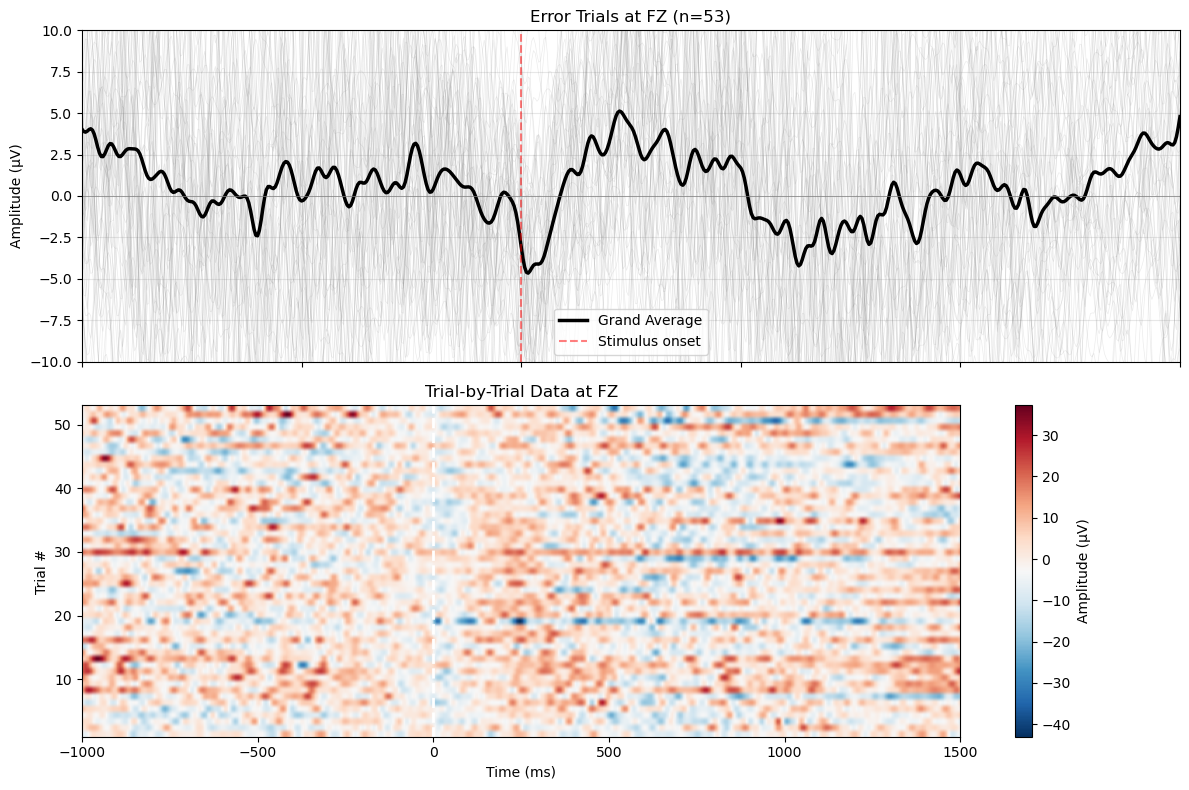

In [3]:
# Extract incorrect trials
incorrect_codes = ['108', '109', '118', '119', '128', '129', '138', '139']
epochs_incorrect = epochs[incorrect_codes]

print(f"Number of error trials: {len(epochs_incorrect)}")

channel = 'FZ'

# Get data: trials x times
data = epochs_incorrect.copy().pick([channel]).get_data()[:, 0, :]  # (n_trials, n_times)
times = epochs_incorrect.times
grand_avg = data.mean(axis=0)

# Convert to microvolts
data_uv = data * 1e6
grand_avg_uv = grand_avg * 1e6

# Plot
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Single trials
ax1.plot(times * 1000, data_uv.T, 'gray', alpha=0.15, linewidth=0.5)
ax1.plot(times * 1000, grand_avg_uv, 'k', linewidth=2.5, label='Grand Average')
ax1.axvline(0, color='r', linestyle='--', alpha=0.5, label='Stimulus onset')
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title(f'Error Trials at {channel} (n={len(epochs_incorrect)})')
ax1.legend()
ax1.grid(alpha=0.3)
ax1.set_xlim([times[0] * 1000, times[-1] * 1000])
ax1.set_ylim([-10, 10])

# Image of all trials
im = ax2.imshow(data_uv, aspect='auto', origin='lower',
                extent=[times[0] * 1000, times[-1] * 1000, 1, len(epochs_incorrect)],
                cmap='RdBu_r')
ax2.axvline(0, color='white', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)')
ax2.set_ylabel('Trial #')
ax2.set_title(f'Trial-by-Trial Data at {channel}')
plt.colorbar(im, ax=ax2, label='Amplitude (µV)')

plt.tight_layout()
plt.show()

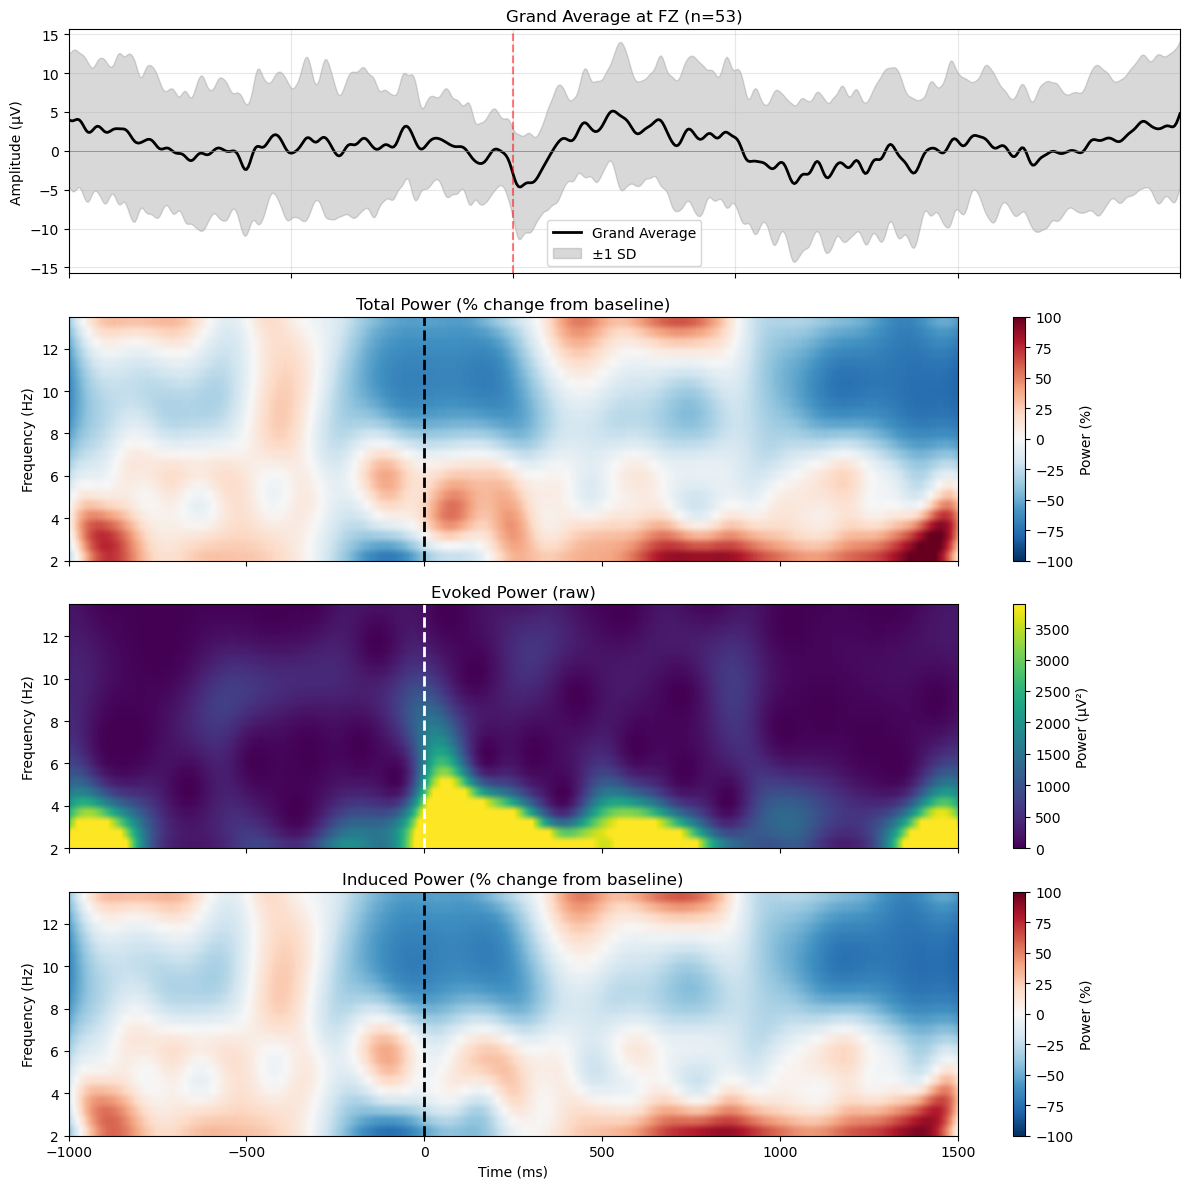

In [4]:
# Time-Frequency Analysis
freqs = np.arange(2, 14, 0.5)  # 2-14 Hz
n_cycles = freqs / 2.0
n_trials = len(data_uv)

sfreq = epochs_incorrect.info['sfreq']
grand_avg = data_uv.mean(axis=0)
sd = data_uv.std(axis=0)

# EVOKED POWER (TFR of averaged signal)
tfr_evoked = np.zeros((len(freqs), len(times)))
for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
    wavelet_duration = min(3 * n_cycle / freq, 0.5)
    wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
    wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
    convolved = np.convolve(grand_avg, wavelet, mode='same')
    tfr_evoked[idx, :] = np.abs(convolved) ** 2

# TOTAL POWER (average of single-trial TFRs)
tfr_total = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(data_uv[trial, :], wavelet, mode='same')
        tfr_total[idx, :] += np.abs(convolved) ** 2
tfr_total /= n_trials

# INDUCED POWER = Total - Evoked
tfr_induced = tfr_total - tfr_evoked

# BASELINE CORRECTION (% change) - only for total and induced
# Define baseline period: -500 to -200 ms
baseline_mask = (times >= -0.5) & (times <= -0.2)

# Compute baseline mean for each frequency
baseline_total = tfr_total[:, baseline_mask].mean(axis=1, keepdims=True)
baseline_induced = tfr_induced[:, baseline_mask].mean(axis=1, keepdims=True)

# Convert to % change (only total and induced)
tfr_total_pct = ((tfr_total - baseline_total) / baseline_total) * 100
tfr_induced_pct = ((tfr_induced - baseline_induced) / baseline_induced) * 100

# Save raw results
tfr_total_raw_pct = tfr_total_pct.copy()
tfr_induced_raw_pct = tfr_induced_pct.copy()

# Plot
fig, axes = plt.subplots(4, 1, figsize=(12, 12), sharex=True)

# Grand average ERP with SD
axes[0].plot(times * 1000, grand_avg, 'k', linewidth=2, label='Grand Average')
axes[0].fill_between(times * 1000, grand_avg - sd, grand_avg + sd, 
                      color='gray', alpha=0.3, label='±1 SD')
axes[0].axvline(0, color='r', linestyle='--', alpha=0.5)
axes[0].axhline(0, color='gray', linestyle='-', linewidth=0.5)
axes[0].set_ylabel('Amplitude (µV)')
axes[0].set_title(f'Grand Average at {channel} (n={n_trials})')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Total Power (baseline corrected)
im1 = axes[1].imshow(tfr_total_pct, aspect='auto', origin='lower', 
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=-100, vmax=100, cmap='RdBu_r')
axes[1].axvline(0, color='black', linestyle='--', linewidth=2)
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_title('Total Power (% change from baseline)')
plt.colorbar(im1, ax=axes[1], label='Power (%)')

# Evoked Power (NOT baseline corrected)
vmax_evoked = np.percentile(tfr_evoked, 95)
im2 = axes[2].imshow(tfr_evoked, aspect='auto', origin='lower', 
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=0, vmax=vmax_evoked, cmap='viridis')
axes[2].axvline(0, color='white', linestyle='--', linewidth=2)
axes[2].set_ylabel('Frequency (Hz)')
axes[2].set_title('Evoked Power (raw)')
plt.colorbar(im2, ax=axes[2], label='Power (µV²)')

# Induced Power (baseline corrected)
im3 = axes[3].imshow(tfr_induced_pct, aspect='auto', origin='lower', 
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=-100, vmax=100, cmap='RdBu_r')
axes[3].axvline(0, color='black', linestyle='--', linewidth=2)
axes[3].set_xlabel('Time (ms)')
axes[3].set_ylabel('Frequency (Hz)')
axes[3].set_title('Induced Power (% change from baseline)')
plt.colorbar(im3, ax=axes[3], label='Power (%)')

plt.tight_layout()
plt.show()

Alignment lags: mean=-4.4 ms, std=38.3 ms


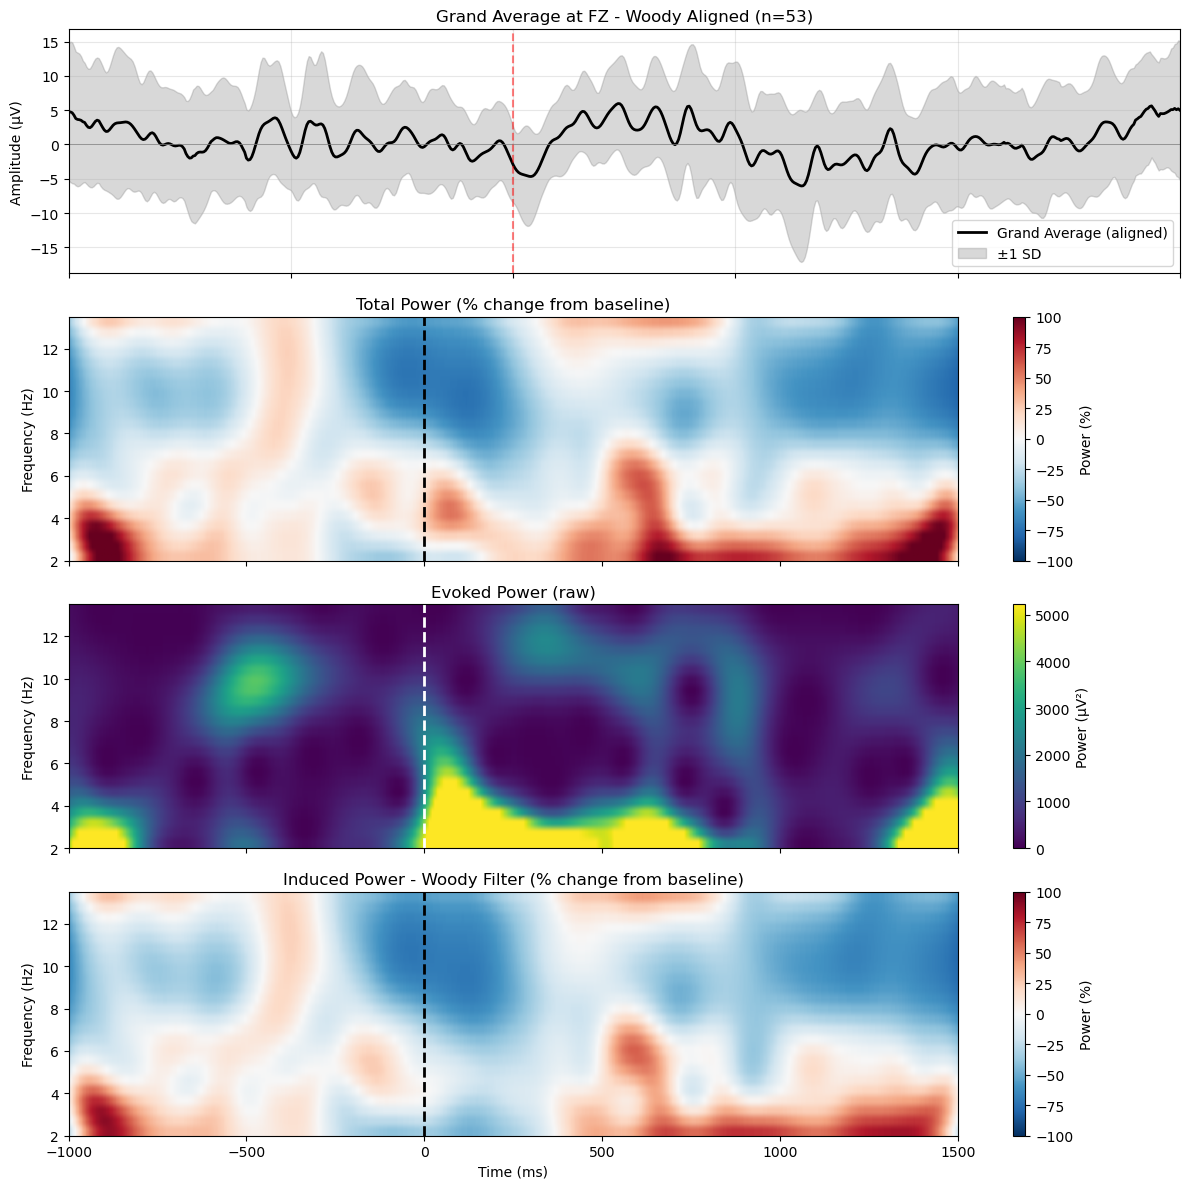

In [5]:
from scipy import signal

def woody_filter(trials, template=None, max_shift=100):
    """Apply Woody filtering to align trials."""
    n_trials, n_times = trials.shape
    
    if template is None:
        template = trials.mean(axis=0)
    
    aligned_trials = np.zeros_like(trials)
    lags = np.zeros(n_trials, dtype=int)
    
    for i in range(n_trials):
        corr = signal.correlate(trials[i, :], template, mode='same')
        center = len(corr) // 2
        search_range = slice(center - max_shift, center + max_shift)
        lag = np.argmax(corr[search_range]) - max_shift
        lags[i] = lag
        aligned_trials[i, :] = np.roll(trials[i, :], -lag)
    
    return aligned_trials, lags

# Apply Woody filter to align trials
aligned_trials, lags = woody_filter(data_uv, max_shift=100)

print(f"Alignment lags: mean={lags.mean():.1f} ms, std={lags.std():.1f} ms")

# Time-Frequency Analysis
freqs = np.arange(2, 14, 0.5)  # 2-14 Hz
n_cycles = freqs / 2.0
n_trials = len(aligned_trials)

sfreq = epochs_incorrect.info['sfreq']

# Grand average from ALIGNED trials
grand_avg_aligned = aligned_trials.mean(axis=0)
sd_aligned = aligned_trials.std(axis=0)

# EVOKED POWER (TFR of aligned averaged signal)
tfr_evoked = np.zeros((len(freqs), len(times)))
for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
    wavelet_duration = min(3 * n_cycle / freq, 0.5)
    wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
    wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
    convolved = np.convolve(grand_avg_aligned, wavelet, mode='same')
    tfr_evoked[idx, :] = np.abs(convolved) ** 2

# TOTAL POWER (average of single-trial TFRs from aligned trials)
tfr_total = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(aligned_trials[trial, :], wavelet, mode='same')
        tfr_total[idx, :] += np.abs(convolved) ** 2
tfr_total /= n_trials

# INDUCED POWER: Subtract aligned ERP from aligned trials, then compute TFR
tfr_induced_woody = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    # Subtract aligned grand average ERP from this aligned trial
    residual = aligned_trials[trial, :] - grand_avg_aligned
    
    # Compute TFR on residual
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(residual, wavelet, mode='same')
        tfr_induced_woody[idx, :] += np.abs(convolved) ** 2
tfr_induced_woody /= n_trials

# BASELINE CORRECTION (% change)
baseline_mask = (times >= -0.5) & (times <= -0.2)

baseline_total = tfr_total[:, baseline_mask].mean(axis=1, keepdims=True)
baseline_induced = tfr_induced_woody[:, baseline_mask].mean(axis=1, keepdims=True)

tfr_total_pct = ((tfr_total - baseline_total) / baseline_total) * 100
tfr_induced_pct = ((tfr_induced_woody - baseline_induced) / baseline_induced) * 100

# Save woody results
tfr_total_woody_pct = tfr_total_pct.copy()
tfr_induced_woody_pct = tfr_induced_pct.copy()

# Plot
fig, axes = plt.subplots(4, 1, figsize=(12, 12), sharex=True)

# Grand average ERP with SD (from aligned trials)
axes[0].plot(times * 1000, grand_avg_aligned, 'k', linewidth=2, label='Grand Average (aligned)')
axes[0].fill_between(times * 1000, grand_avg_aligned - sd_aligned, grand_avg_aligned + sd_aligned, 
                      color='gray', alpha=0.3, label='±1 SD')
axes[0].axvline(0, color='r', linestyle='--', alpha=0.5)
axes[0].axhline(0, color='gray', linestyle='-', linewidth=0.5)
axes[0].set_ylabel('Amplitude (µV)')
axes[0].set_title(f'Grand Average at {channel} - Woody Aligned (n={n_trials})')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Total Power (baseline corrected)
im1 = axes[1].imshow(tfr_total_pct, aspect='auto', origin='lower', 
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=-100, vmax=100, cmap='RdBu_r')
axes[1].axvline(0, color='black', linestyle='--', linewidth=2)
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_title('Total Power (% change from baseline)')
plt.colorbar(im1, ax=axes[1], label='Power (%)')

# Evoked Power (NOT baseline corrected)
vmax_evoked = np.percentile(tfr_evoked, 95)
im2 = axes[2].imshow(tfr_evoked, aspect='auto', origin='lower', 
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=0, vmax=vmax_evoked, cmap='viridis')
axes[2].axvline(0, color='white', linestyle='--', linewidth=2)
axes[2].set_ylabel('Frequency (Hz)')
axes[2].set_title('Evoked Power (raw)')
plt.colorbar(im2, ax=axes[2], label='Power (µV²)')

# Induced Power with Woody Filter (baseline corrected)
im3 = axes[3].imshow(tfr_induced_pct, aspect='auto', origin='lower', 
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=-100, vmax=100, cmap='RdBu_r')
axes[3].axvline(0, color='black', linestyle='--', linewidth=2)
axes[3].set_xlabel('Time (ms)')
axes[3].set_ylabel('Frequency (Hz)')
axes[3].set_title('Induced Power - Woody Filter (% change from baseline)')
plt.colorbar(im3, ax=axes[3], label='Power (%)')

plt.tight_layout()
plt.show()

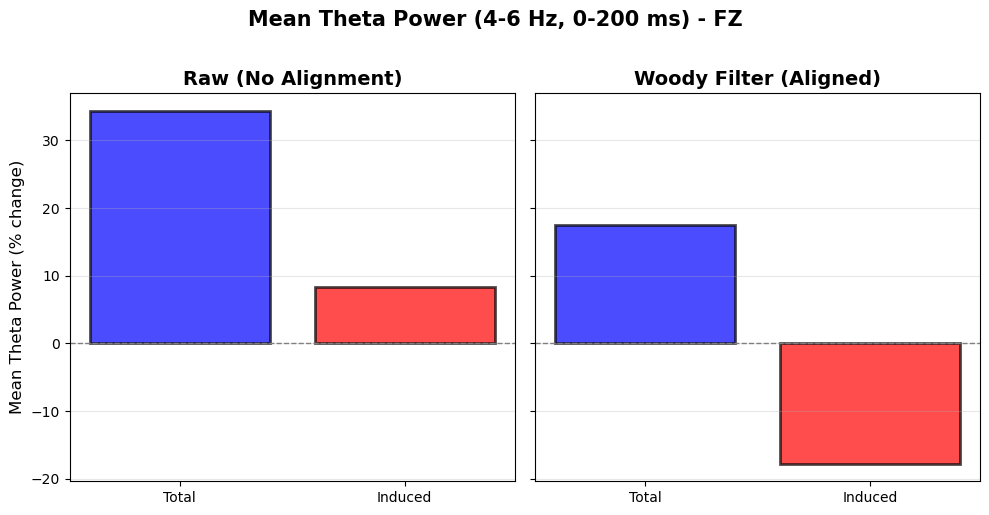

Raw - Total: 34.34%, Induced: 8.35%
Woody - Total: 17.53%, Induced: -17.77%


In [6]:
# Extract theta band (4-6 Hz) and average over 0-200 ms
theta_mask = (freqs >= 4) & (freqs <= 6)
time_mask = (times >= 0) & (times <= 0.20)

# Calculate mean theta power
# From Raw analysis
mean_theta_total_raw = tfr_total_raw_pct[theta_mask, :][:, time_mask].mean()
mean_theta_induced_raw = tfr_induced_raw_pct[theta_mask, :][:, time_mask].mean()

# From Woody analysis  
mean_theta_total_woody = tfr_total_woody_pct[theta_mask, :][:, time_mask].mean()
mean_theta_induced_woody = tfr_induced_woody_pct[theta_mask, :][:, time_mask].mean()

# Plot with shared y-axis
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5), sharey=True)

# Raw
conditions_raw = ['Total', 'Induced']
values_raw = [mean_theta_total_raw, mean_theta_induced_raw]
colors_raw = ['blue', 'red']
ax1.bar(conditions_raw, values_raw, color=colors_raw, alpha=0.7, edgecolor='black', linewidth=2)
ax1.axhline(0, color='gray', linestyle='--', linewidth=1)
ax1.set_ylabel('Mean Theta Power (% change)', fontsize=12)
ax1.set_title('Raw (No Alignment)', fontsize=14, fontweight='bold')
ax1.grid(alpha=0.3, axis='y')

# Woody
conditions_woody = ['Total', 'Induced']
values_woody = [mean_theta_total_woody, mean_theta_induced_woody]
colors_woody = ['blue', 'red']
ax2.bar(conditions_woody, values_woody, color=colors_woody, alpha=0.7, edgecolor='black', linewidth=2)
ax2.axhline(0, color='gray', linestyle='--', linewidth=1)
ax2.set_title('Woody Filter (Aligned)', fontsize=14, fontweight='bold')
ax2.grid(alpha=0.3, axis='y')

plt.suptitle(f'Mean Theta Power (4-6 Hz, 0-200 ms) - {channel}', 
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f"Raw - Total: {mean_theta_total_raw:.2f}%, Induced: {mean_theta_induced_raw:.2f}%")
print(f"Woody - Total: {mean_theta_total_woody:.2f}%, Induced: {mean_theta_induced_woody:.2f}%")

Alignment lags: mean=-4.4 ms, std=38.3 ms


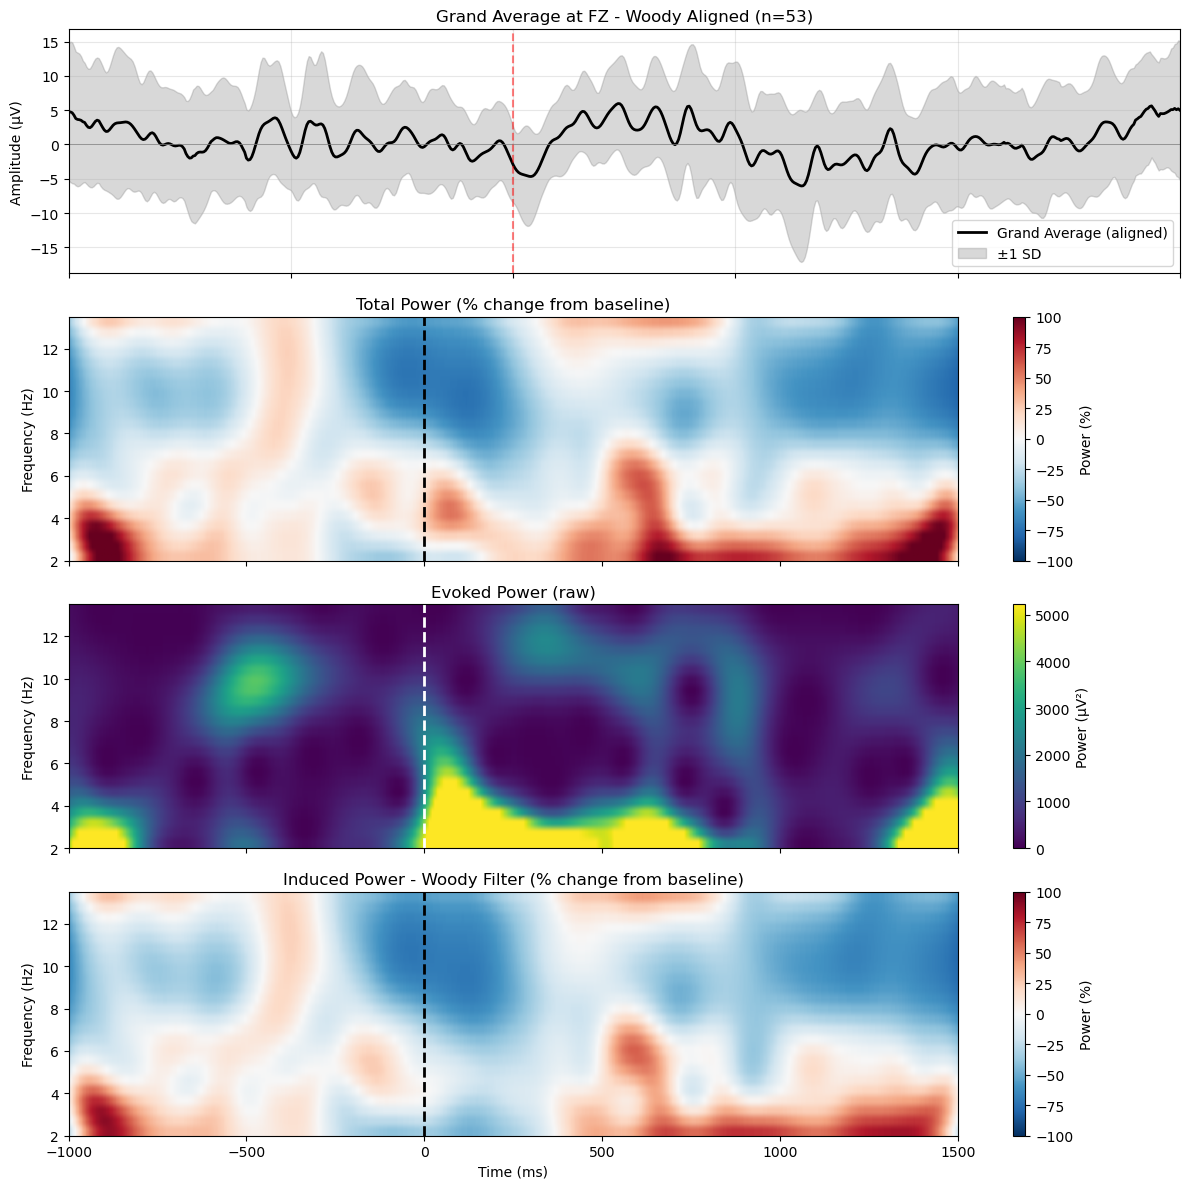

In [7]:
from scipy import signal

def woody_filter(trials, template=None, max_shift=100):
    """Apply Woody filtering to align trials."""
    n_trials, n_times = trials.shape
    
    if template is None:
        template = trials.mean(axis=0)
    
    aligned_trials = np.zeros_like(trials)
    lags = np.zeros(n_trials, dtype=int)
    
    for i in range(n_trials):
        corr = signal.correlate(trials[i, :], template, mode='same')
        center = len(corr) // 2
        search_range = slice(center - max_shift, center + max_shift)
        lag = np.argmax(corr[search_range]) - max_shift
        lags[i] = lag
        aligned_trials[i, :] = np.roll(trials[i, :], -lag)
    
    return aligned_trials, lags

# Apply Woody filter to align trials
aligned_trials, lags = woody_filter(data_uv, max_shift=100)

print(f"Alignment lags: mean={lags.mean():.1f} ms, std={lags.std():.1f} ms")

# Time-Frequency Analysis
freqs = np.arange(2, 14, 0.5)  # 2-14 Hz
n_cycles = freqs / 2.0
n_trials = len(aligned_trials)

sfreq = epochs_incorrect.info['sfreq']

# Grand average from ALIGNED trials
grand_avg_aligned = aligned_trials.mean(axis=0)
sd_aligned = aligned_trials.std(axis=0)

# EVOKED POWER (TFR of aligned averaged signal)
tfr_evoked = np.zeros((len(freqs), len(times)))
for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
    wavelet_duration = min(3 * n_cycle / freq, 0.5)
    wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
    wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
    convolved = np.convolve(grand_avg_aligned, wavelet, mode='same')
    tfr_evoked[idx, :] = np.abs(convolved) ** 2

# TOTAL POWER (average of single-trial TFRs from aligned trials)
tfr_total = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(aligned_trials[trial, :], wavelet, mode='same')
        tfr_total[idx, :] += np.abs(convolved) ** 2
tfr_total /= n_trials

# INDUCED POWER: Subtract aligned ERP from aligned trials, then compute TFR
tfr_induced_woody = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    # Subtract aligned grand average ERP from this aligned trial
    residual = aligned_trials[trial, :] - grand_avg_aligned
    
    # Compute TFR on residual
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(residual, wavelet, mode='same')
        tfr_induced_woody[idx, :] += np.abs(convolved) ** 2
tfr_induced_woody /= n_trials

# BASELINE CORRECTION (% change)
baseline_mask = (times >= -0.5) & (times <= -0.2)

baseline_total = tfr_total[:, baseline_mask].mean(axis=1, keepdims=True)
baseline_induced = tfr_induced_woody[:, baseline_mask].mean(axis=1, keepdims=True)

tfr_total_pct = ((tfr_total - baseline_total) / baseline_total) * 100
tfr_induced_pct = ((tfr_induced_woody - baseline_induced) / baseline_induced) * 100

# Save woody results
tfr_total_woody_pct = tfr_total_pct.copy()
tfr_induced_woody_pct = tfr_induced_pct.copy()

# Plot
fig, axes = plt.subplots(4, 1, figsize=(12, 12), sharex=True)

# Grand average ERP with SD (from aligned trials)
axes[0].plot(times * 1000, grand_avg_aligned, 'k', linewidth=2, label='Grand Average (aligned)')
axes[0].fill_between(times * 1000, grand_avg_aligned - sd_aligned, grand_avg_aligned + sd_aligned, 
                      color='gray', alpha=0.3, label='±1 SD')
axes[0].axvline(0, color='r', linestyle='--', alpha=0.5)
axes[0].axhline(0, color='gray', linestyle='-', linewidth=0.5)
axes[0].set_ylabel('Amplitude (µV)')
axes[0].set_title(f'Grand Average at {channel} - Woody Aligned (n={n_trials})')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Total Power (baseline corrected)
im1 = axes[1].imshow(tfr_total_pct, aspect='auto', origin='lower', 
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=-100, vmax=100, cmap='RdBu_r')
axes[1].axvline(0, color='black', linestyle='--', linewidth=2)
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_title('Total Power (% change from baseline)')
plt.colorbar(im1, ax=axes[1], label='Power (%)')

# Evoked Power (NOT baseline corrected)
vmax_evoked = np.percentile(tfr_evoked, 95)
im2 = axes[2].imshow(tfr_evoked, aspect='auto', origin='lower', 
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=0, vmax=vmax_evoked, cmap='viridis')
axes[2].axvline(0, color='white', linestyle='--', linewidth=2)
axes[2].set_ylabel('Frequency (Hz)')
axes[2].set_title('Evoked Power (raw)')
plt.colorbar(im2, ax=axes[2], label='Power (µV²)')

# Induced Power with Woody Filter (baseline corrected)
im3 = axes[3].imshow(tfr_induced_pct, aspect='auto', origin='lower', 
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=-100, vmax=100, cmap='RdBu_r')
axes[3].axvline(0, color='black', linestyle='--', linewidth=2)
axes[3].set_xlabel('Time (ms)')
axes[3].set_ylabel('Frequency (Hz)')
axes[3].set_title('Induced Power - Woody Filter (% change from baseline)')
plt.colorbar(im3, ax=axes[3], label='Power (%)')

plt.tight_layout()
plt.show()

Processing subjects: 100%|██████████| 156/156 [01:36<00:00,  1.61it/s]


155 subjects analyzed successfully


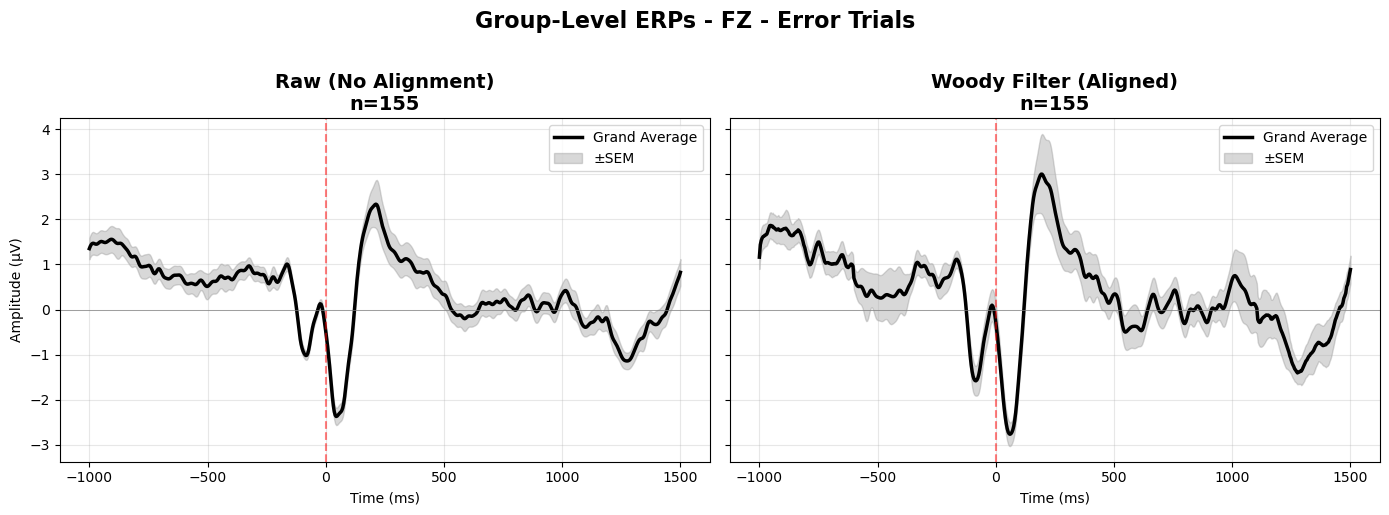

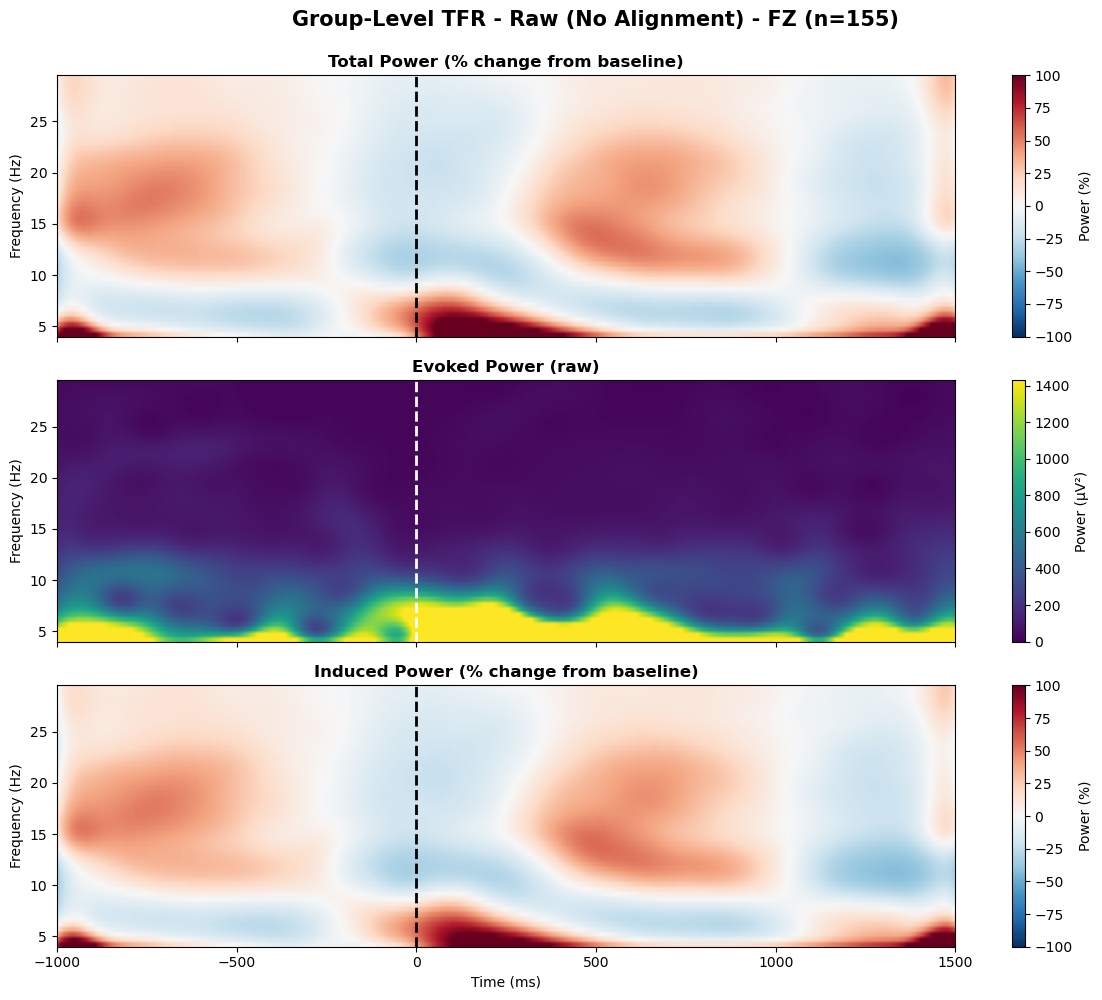

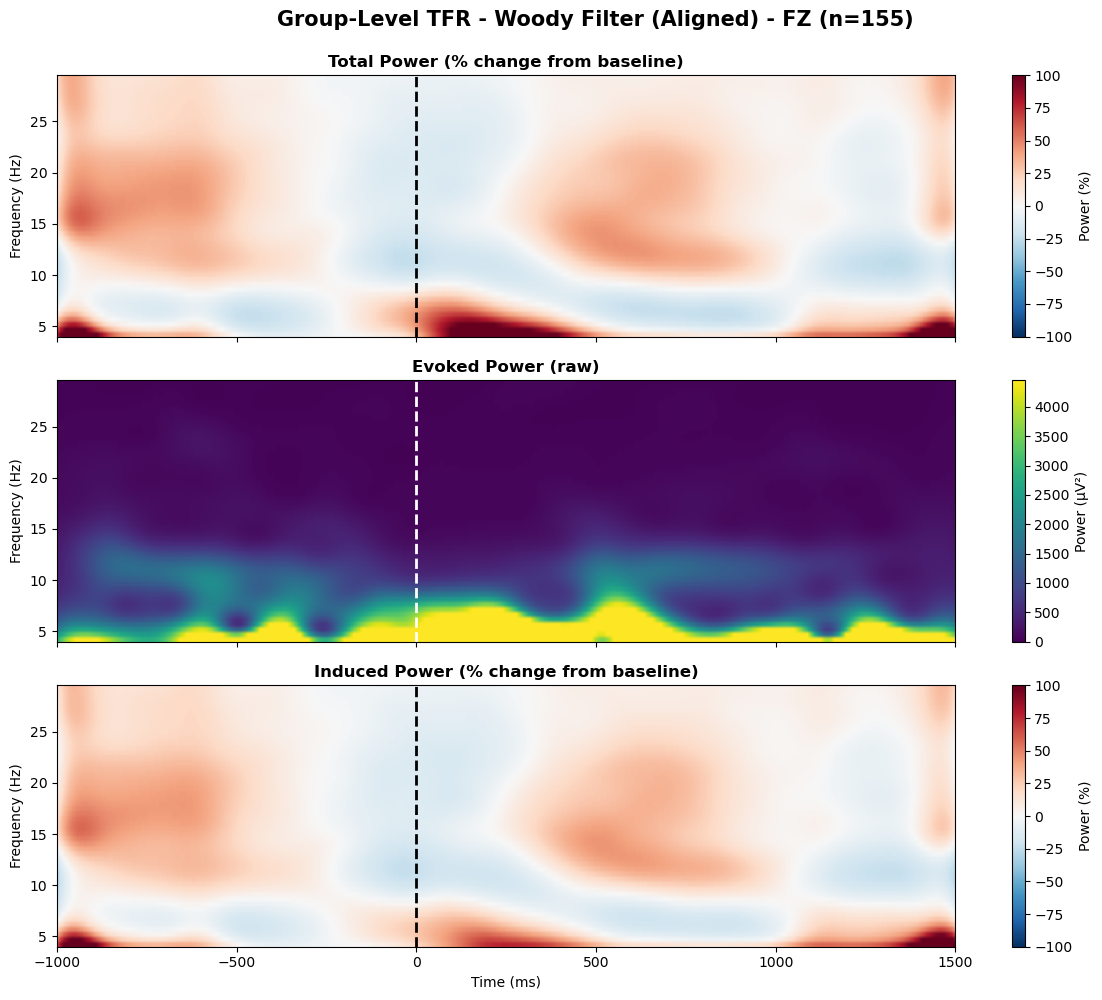

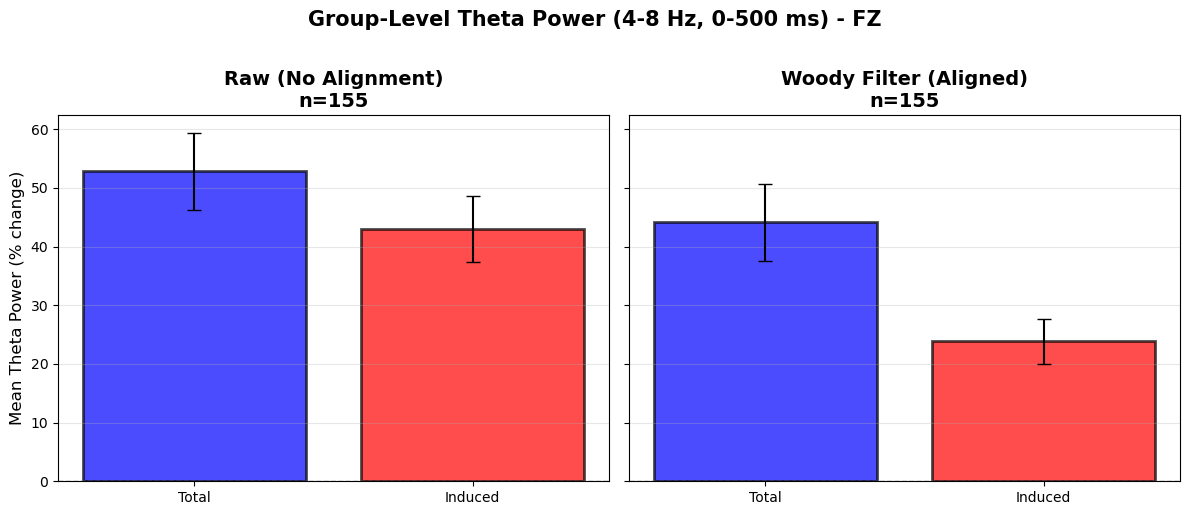


=== SUMMARY STATISTICS ===
Raw - Total: 52.82±6.60%, Induced: 42.98±5.58%
Woody - Total: 44.14±6.57%, Induced: 23.86±3.85%

Results saved to 'theta_analysis_results.csv'


In [8]:
# Suppress warnings
import warnings
import pandas as pd
warnings.filterwarnings('ignore')

def woody_filter(trials, template=None, max_shift=100):
    """Apply Woody filtering to align trials."""
    n_trials, n_times = trials.shape
    
    if template is None:
        template = trials.mean(axis=0)
    
    aligned_trials = np.zeros_like(trials)
    lags = np.zeros(n_trials, dtype=int)
    
    for i in range(n_trials):
        corr = signal.correlate(trials[i, :], template, mode='same')
        center = len(corr) // 2
        search_range = slice(center - max_shift, center + max_shift)
        lag = np.argmax(corr[search_range]) - max_shift
        lags[i] = lag
        aligned_trials[i, :] = np.roll(trials[i, :], -lag)
    
    return aligned_trials, lags

def analyze_subject(epochs_path, channel='FZ', theta_range=(4, 8), time_window=(0, 0.5)):
    """Analyze one subject: compute Raw and Woody TFR."""
    
    # Load epochs
    epochs = mne.read_epochs(epochs_path, preload=True, verbose=False)
    
    # Extract incorrect trials
    incorrect_codes = ['108', '109', '118', '119', '128', '129', '138', '139']
    epochs_incorrect = epochs[incorrect_codes]
    
    n_trials = len(epochs_incorrect)
    if n_trials < 5:
        return None
    
    # Get data
    data = epochs_incorrect.copy().pick([channel]).get_data()[:, 0, :]
    times = epochs_incorrect.times
    data_uv = data * 1e6
    sfreq = epochs_incorrect.info['sfreq']
    
    # TFR parameters
    freqs = np.arange(4, 30, 0.5)
    n_cycles = freqs / 2.0
    baseline_mask = (times >= -0.5) & (times <= 0)  # -500 to 0 ms baseline
    
    # === RAW ANALYSIS ===
    grand_avg_raw = data_uv.mean(axis=0)
    sd_raw = data_uv.std(axis=0)
    
    # Raw - Total Power
    tfr_total_raw = np.zeros((len(freqs), len(times)))
    for trial in range(n_trials):
        for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
            wavelet_duration = min(3 * n_cycle / freq, 0.5)
            wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
            wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
            convolved = np.convolve(data_uv[trial, :], wavelet, mode='same')
            tfr_total_raw[idx, :] += np.abs(convolved) ** 2
    tfr_total_raw /= n_trials
    
    # Raw - Evoked Power
    tfr_evoked_raw = np.zeros((len(freqs), len(times)))
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(grand_avg_raw, wavelet, mode='same')
        tfr_evoked_raw[idx, :] = np.abs(convolved) ** 2
    
    # Raw - Induced Power
    tfr_induced_raw = np.zeros((len(freqs), len(times)))
    for trial in range(n_trials):
        residual = data_uv[trial, :] - grand_avg_raw
        for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
            wavelet_duration = min(3 * n_cycle / freq, 0.5)
            wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
            wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
            convolved = np.convolve(residual, wavelet, mode='same')
            tfr_induced_raw[idx, :] += np.abs(convolved) ** 2
    tfr_induced_raw /= n_trials
    
    # Baseline correction
    bl_total_raw = tfr_total_raw[:, baseline_mask].mean(axis=1, keepdims=True)
    bl_induced_raw = tfr_induced_raw[:, baseline_mask].mean(axis=1, keepdims=True)
    tfr_total_raw_pct = ((tfr_total_raw - bl_total_raw) / bl_total_raw) * 100
    tfr_induced_raw_pct = ((tfr_induced_raw - bl_induced_raw) / bl_induced_raw) * 100
    
    # === WOODY ANALYSIS ===
    aligned_trials, lags = woody_filter(data_uv, max_shift=100)
    grand_avg_woody = aligned_trials.mean(axis=0)
    sd_woody = aligned_trials.std(axis=0)
    
    # Woody - Total Power
    tfr_total_woody = np.zeros((len(freqs), len(times)))
    for trial in range(n_trials):
        for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
            wavelet_duration = min(3 * n_cycle / freq, 0.5)
            wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
            wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
            convolved = np.convolve(aligned_trials[trial, :], wavelet, mode='same')
            tfr_total_woody[idx, :] += np.abs(convolved) ** 2
    tfr_total_woody /= n_trials
    
    # Woody - Evoked Power
    tfr_evoked_woody = np.zeros((len(freqs), len(times)))
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(grand_avg_woody, wavelet, mode='same')
        tfr_evoked_woody[idx, :] = np.abs(convolved) ** 2
    
    # Woody - Induced Power
    tfr_induced_woody = np.zeros((len(freqs), len(times)))
    for trial in range(n_trials):
        residual = aligned_trials[trial, :] - grand_avg_woody
        for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
            wavelet_duration = min(3 * n_cycle / freq, 0.5)
            wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
            wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
            convolved = np.convolve(residual, wavelet, mode='same')
            tfr_induced_woody[idx, :] += np.abs(convolved) ** 2
    tfr_induced_woody /= n_trials
    
    # Baseline correction
    bl_total_woody = tfr_total_woody[:, baseline_mask].mean(axis=1, keepdims=True)
    bl_induced_woody = tfr_induced_woody[:, baseline_mask].mean(axis=1, keepdims=True)
    tfr_total_woody_pct = ((tfr_total_woody - bl_total_woody) / bl_total_woody) * 100
    tfr_induced_woody_pct = ((tfr_induced_woody - bl_induced_woody) / bl_induced_woody) * 100
    
    # === EXTRACT THETA ===
    theta_mask = (freqs >= theta_range[0]) & (freqs <= theta_range[1])
    time_mask = (times >= time_window[0]) & (times <= time_window[1])
    
    results = {
        'n_trials': n_trials,
        'mean_lag': lags.mean(),
        'std_lag': lags.std(),
        'theta_total_raw': tfr_total_raw_pct[theta_mask, :][:, time_mask].mean(),
        'theta_induced_raw': tfr_induced_raw_pct[theta_mask, :][:, time_mask].mean(),
        'theta_total_woody': tfr_total_woody_pct[theta_mask, :][:, time_mask].mean(),
        'theta_induced_woody': tfr_induced_woody_pct[theta_mask, :][:, time_mask].mean(),
        'erp_raw': grand_avg_raw,
        'sd_raw': sd_raw,
        'erp_woody': grand_avg_woody,
        'sd_woody': sd_woody,
        'tfr_total_raw_pct': tfr_total_raw_pct,
        'tfr_evoked_raw': tfr_evoked_raw,
        'tfr_induced_raw_pct': tfr_induced_raw_pct,
        'tfr_total_woody_pct': tfr_total_woody_pct,
        'tfr_evoked_woody': tfr_evoked_woody,
        'tfr_induced_woody_pct': tfr_induced_woody_pct,
        'times': times,
        'freqs': freqs
    }
    
    return results

# === MAIN ANALYSIS ===
subjects = ['sub-AG05AS29', 'sub-AH17AR05', 'sub-AL07NK06', 'sub-AL08AS02', 'sub-AR06AS06', 
            'sub-AR10IO04', 'sub-AT06ED25', 'sub-AU09GE22', 'sub-CH04ER19', 'sub-CH05NK28', 
            'sub-CH06UT07', 'sub-CH07AD15', 'sub-CH09AS13', 'sub-CK04NS18', 'sub-CK06ED08', 
            'sub-CK06ST11', 'sub-CK06US15', 'sub-DADARE11', 'sub-DT05EV26', 'sub-DT07ES22', 
            'sub-DTINTZ10', 'sub-EK05AN14', 'sub-EK06ER26', 'sub-EK07CH24', 'sub-EL05JO26', 
            'sub-EL06LD17', 'sub-EL07EL14', 'sub-EN04ER01', 'sub-EN05AN02', 'sub-EN05KT02', 
            'sub-EN05US05', 'sub-EN06AN21', 'sub-EN08CH27', 'sub-EP05EN09', 'sub-ER03ER09', 
            'sub-ER04ER12', 'sub-ER04RT24', 'sub-ER05AN13', 'sub-ER05AV01', 'sub-ER05EL09', 
            'sub-ER05EL26', 'sub-ER05ER07', 'sub-ER05IM29', 'sub-ER05MA17', 'sub-ER05NG11', 
            'sub-ER05RK06', 'sub-ER05RT24', 'sub-ER06EL06', 'sub-ER06EN27', 'sub-ER06ET15', 
            'sub-ER06IS22', 'sub-ER06US24', 'sub-ER07AN28', 'sub-ER07AS24', 'sub-ER07EF15', 
            'sub-ER07EL10', 'sub-ER07ER23', 'sub-ER07ER30', 'sub-ER07RL02', 'sub-ER08AS28', 
            'sub-ER08EN05', 'sub-ER09NK30', 'sub-ES06ER27', 'sub-ES06NK11', 'sub-EZ04SE15', 
            'sub-GA04LI18', 'sub-HEERLD19', 'sub-IA05NS20', 'sub-ID07EN28', 'sub-IG06AI28', 
            'sub-IG06LF01', 'sub-IG06NS07', 'sub-IG06WE03', 'sub-IG07RT16', 'sub-IK06ET06', 
            'sub-IK09LD05', 'sub-IN05ED23', 'sub-IN06AS14', 'sub-IS06RG09', 'sub-IT08ND26', 
            'sub-JU05IN24', 'sub-KA04LF11', 'sub-KE05AN23', 'sub-KE07AN05', 'sub-KE07ER04', 
            'sub-KE08AS23', 'sub-KN05EN09', 'sub-KO07EL16', 'sub-LA08RE26', 'sub-LO06RE10', 
            'sub-LY07EL23', 'sub-MA06LO21', 'sub-ME05NS04', 'sub-NA04AV25', 'sub-ND05NG06', 
            'sub-ND06EF01', 'sub-NE06AS01', 'sub-NE06EL01', 'sub-NG03YI17', 'sub-NG06EA08', 
            'sub-NK06AS24', 'sub-NK06RG30', 'sub-NN04AN24', 'sub-NN05AN05', 'sub-NN05IR17', 
            'sub-NN06TH16', 'sub-NN07EN14', 'sub-NN07ID18', 'sub-NN08AS03', 'sub-NN08EL29', 
            'sub-NN08ER22', 'sub-NN08LM06', 'sub-NN09LM18', 'sub-NN09NS31', 'sub-NO05RT22', 
            'sub-NS09EL05', 'sub-NY04DT26', 'sub-NZ04EN16', 'sub-NZ09ER04', 'sub-OH05NK29', 
            'sub-ON05EL22', 'sub-OW07RK26', 'sub-PP07AS29', 'sub-RASUAN07', 'sub-RF09EL18', 
            'sub-RG05RS16', 'sub-RG06AS09', 'sub-RO06AN18', 'sub-RT07LD06', 'sub-RYRAAN26', 
            'sub-RZ05ND19', 'sub-SA05AH22', 'sub-SE05AS26', 'sub-SE05ZI24', 'sub-SE06AM29', 
            'sub-SE06NS17', 'sub-ST03ED03', 'sub-ST07NK15', 'sub-TA03RL11', 'sub-TE05AS09', 
            'sub-TE05NS01', 'sub-TE10AN12', 'sub-TH07AR12', 'sub-TH08ER21', 'sub-TT06LF28', 
            'sub-TT08NS17', 'sub-TZ08US31', 'sub-US07US10', 'sub-US08KE27', 'sub-VA05AS27', 
            'sub-VA05OR26', 'sub-VA06NZ29', 'sub-VA06OV12', 'sub-WA04EJ22', 'sub-WA05EJ08', 
            'sub-XX04AS28']

data_dir = Path("/Users/qmoreau/Documents/Work/flanker_bursts/PreprocessedData/ernpipeline/")

# Analyze all subjects with progress bar
all_results = []
for sub_id in tqdm(subjects, desc="Processing subjects"):
    sub_file = data_dir / sub_id / f"{sub_id}_desc-epochs_eeg.fif"
    
    if not sub_file.exists():
        continue
    
    try:
        results = analyze_subject(sub_file, channel='FZ', theta_range=(4, 8), time_window=(0, 0.5))
        if results is not None:
            results['subject'] = sub_id
            all_results.append(results)
    except:
        continue

print(f"\n{len(all_results)} subjects analyzed successfully")

# === COMPUTE GROUP AVERAGES ===
times = all_results[0]['times']
freqs = all_results[0]['freqs']

erp_raw_all = np.array([r['erp_raw'] for r in all_results])
erp_woody_all = np.array([r['erp_woody'] for r in all_results])
erp_raw_mean = erp_raw_all.mean(axis=0)
erp_raw_sem = erp_raw_all.std(axis=0) / np.sqrt(len(all_results))
erp_woody_mean = erp_woody_all.mean(axis=0)
erp_woody_sem = erp_woody_all.std(axis=0) / np.sqrt(len(all_results))

tfr_total_raw_all = np.array([r['tfr_total_raw_pct'] for r in all_results])
tfr_evoked_raw_all = np.array([r['tfr_evoked_raw'] for r in all_results])
tfr_induced_raw_all = np.array([r['tfr_induced_raw_pct'] for r in all_results])
tfr_total_woody_all = np.array([r['tfr_total_woody_pct'] for r in all_results])
tfr_evoked_woody_all = np.array([r['tfr_evoked_woody'] for r in all_results])
tfr_induced_woody_all = np.array([r['tfr_induced_woody_pct'] for r in all_results])

tfr_total_raw_mean = tfr_total_raw_all.mean(axis=0)
tfr_evoked_raw_mean = tfr_evoked_raw_all.mean(axis=0)
tfr_induced_raw_mean = tfr_induced_raw_all.mean(axis=0)
tfr_total_woody_mean = tfr_total_woody_all.mean(axis=0)
tfr_evoked_woody_mean = tfr_evoked_woody_all.mean(axis=0)
tfr_induced_woody_mean = tfr_induced_woody_all.mean(axis=0)

# === PLOT 1: ERPs ===
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

ax1.plot(times * 1000, erp_raw_mean, 'k', linewidth=2.5, label='Grand Average')
ax1.fill_between(times * 1000, erp_raw_mean - erp_raw_sem, erp_raw_mean + erp_raw_sem,
                  color='gray', alpha=0.3, label='±SEM')
ax1.axvline(0, color='r', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title(f'Raw (No Alignment)\nn={len(all_results)}', fontsize=14, fontweight='bold')
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(times * 1000, erp_woody_mean, 'k', linewidth=2.5, label='Grand Average')
ax2.fill_between(times * 1000, erp_woody_mean - erp_woody_sem, erp_woody_mean + erp_woody_sem,
                  color='gray', alpha=0.3, label='±SEM')
ax2.axvline(0, color='r', linestyle='--', alpha=0.5)
ax2.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax2.set_xlabel('Time (ms)')
ax2.set_title(f'Woody Filter (Aligned)\nn={len(all_results)}', fontsize=14, fontweight='bold')
ax2.legend()
ax2.grid(alpha=0.3)

plt.suptitle('Group-Level ERPs - FZ - Error Trials', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# === PLOT 2: TFRs RAW ===
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

im1 = axes[0].imshow(tfr_total_raw_mean, aspect='auto', origin='lower',
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=-100, vmax=100, cmap='RdBu_r')
axes[0].axvline(0, color='black', linestyle='--', linewidth=2)
axes[0].set_ylabel('Frequency (Hz)')
axes[0].set_title('Total Power (% change from baseline)', fontweight='bold')
plt.colorbar(im1, ax=axes[0], label='Power (%)')

vmax_evoked = np.percentile(tfr_evoked_raw_mean, 95)
im2 = axes[1].imshow(tfr_evoked_raw_mean, aspect='auto', origin='lower',
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=0, vmax=vmax_evoked, cmap='viridis')
axes[1].axvline(0, color='white', linestyle='--', linewidth=2)
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_title('Evoked Power (raw)', fontweight='bold')
plt.colorbar(im2, ax=axes[1], label='Power (µV²)')

im3 = axes[2].imshow(tfr_induced_raw_mean, aspect='auto', origin='lower',
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=-100, vmax=100, cmap='RdBu_r')
axes[2].axvline(0, color='black', linestyle='--', linewidth=2)
axes[2].set_xlabel('Time (ms)')
axes[2].set_ylabel('Frequency (Hz)')
axes[2].set_title('Induced Power (% change from baseline)', fontweight='bold')
plt.colorbar(im3, ax=axes[2], label='Power (%)')

plt.suptitle(f'Group-Level TFR - Raw (No Alignment) - FZ (n={len(all_results)})',
             fontsize=15, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

# === PLOT 3: TFRs WOODY ===
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

im1 = axes[0].imshow(tfr_total_woody_mean, aspect='auto', origin='lower',
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=-100, vmax=100, cmap='RdBu_r')
axes[0].axvline(0, color='black', linestyle='--', linewidth=2)
axes[0].set_ylabel('Frequency (Hz)')
axes[0].set_title('Total Power (% change from baseline)', fontweight='bold')
plt.colorbar(im1, ax=axes[0], label='Power (%)')

vmax_evoked = np.percentile(tfr_evoked_woody_mean, 95)
im2 = axes[1].imshow(tfr_evoked_woody_mean, aspect='auto', origin='lower',
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=0, vmax=vmax_evoked, cmap='viridis')
axes[1].axvline(0, color='white', linestyle='--', linewidth=2)
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_title('Evoked Power (raw)', fontweight='bold')
plt.colorbar(im2, ax=axes[1], label='Power (µV²)')

im3 = axes[2].imshow(tfr_induced_woody_mean, aspect='auto', origin='lower',
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=-100, vmax=100, cmap='RdBu_r')
axes[2].axvline(0, color='black', linestyle='--', linewidth=2)
axes[2].set_xlabel('Time (ms)')
axes[2].set_ylabel('Frequency (Hz)')
axes[2].set_title('Induced Power (% change from baseline)', fontweight='bold')
plt.colorbar(im3, ax=axes[2], label='Power (%)')

plt.suptitle(f'Group-Level TFR - Woody Filter (Aligned) - FZ (n={len(all_results)})',
             fontsize=15, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

# === PLOT 4: THETA BARPLOTS ===
df = pd.DataFrame([{k: v for k, v in r.items() if k not in ['erp_raw', 'sd_raw', 'erp_woody', 'sd_woody',
                                                               'tfr_total_raw_pct', 'tfr_evoked_raw', 'tfr_induced_raw_pct',
                                                               'tfr_total_woody_pct', 'tfr_evoked_woody', 'tfr_induced_woody_pct',
                                                               'times', 'freqs']} for r in all_results])

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

raw_means = [df['theta_total_raw'].mean(), df['theta_induced_raw'].mean()]
raw_sems = [df['theta_total_raw'].sem(), df['theta_induced_raw'].sem()]
x_pos = np.arange(len(raw_means))
axes[0].bar(x_pos, raw_means, yerr=raw_sems, color=['blue', 'red'],
            alpha=0.7, edgecolor='black', linewidth=2, capsize=5)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(['Total', 'Induced'])
axes[0].axhline(0, color='gray', linestyle='--', linewidth=1)
axes[0].set_ylabel('Mean Theta Power (% change)', fontsize=12)
axes[0].set_title(f'Raw (No Alignment)\nn={len(df)}', fontsize=14, fontweight='bold')
axes[0].grid(alpha=0.3, axis='y')

woody_means = [df['theta_total_woody'].mean(), df['theta_induced_woody'].mean()]
woody_sems = [df['theta_total_woody'].sem(), df['theta_induced_woody'].sem()]
axes[1].bar(x_pos, woody_means, yerr=woody_sems, color=['blue', 'red'],
            alpha=0.7, edgecolor='black', linewidth=2, capsize=5)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(['Total', 'Induced'])
axes[1].axhline(0, color='gray', linestyle='--', linewidth=1)
axes[1].set_title(f'Woody Filter (Aligned)\nn={len(df)}', fontsize=14, fontweight='bold')
axes[1].grid(alpha=0.3, axis='y')

plt.suptitle('Group-Level Theta Power (4-8 Hz, 0-500 ms) - FZ',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\n=== SUMMARY STATISTICS ===")
print(f"Raw - Total: {raw_means[0]:.2f}±{raw_sems[0]:.2f}%, Induced: {raw_means[1]:.2f}±{raw_sems[1]:.2f}%")
print(f"Woody - Total: {woody_means[0]:.2f}±{woody_sems[0]:.2f}%, Induced: {woody_means[1]:.2f}±{woody_sems[1]:.2f}%")

df.to_csv('theta_analysis_results.csv', index=False)
print("\nResults saved to 'theta_analysis_results.csv'")

Processing subjects: 100%|██████████| 156/156 [05:55<00:00,  2.28s/it]


156 subjects analyzed successfully


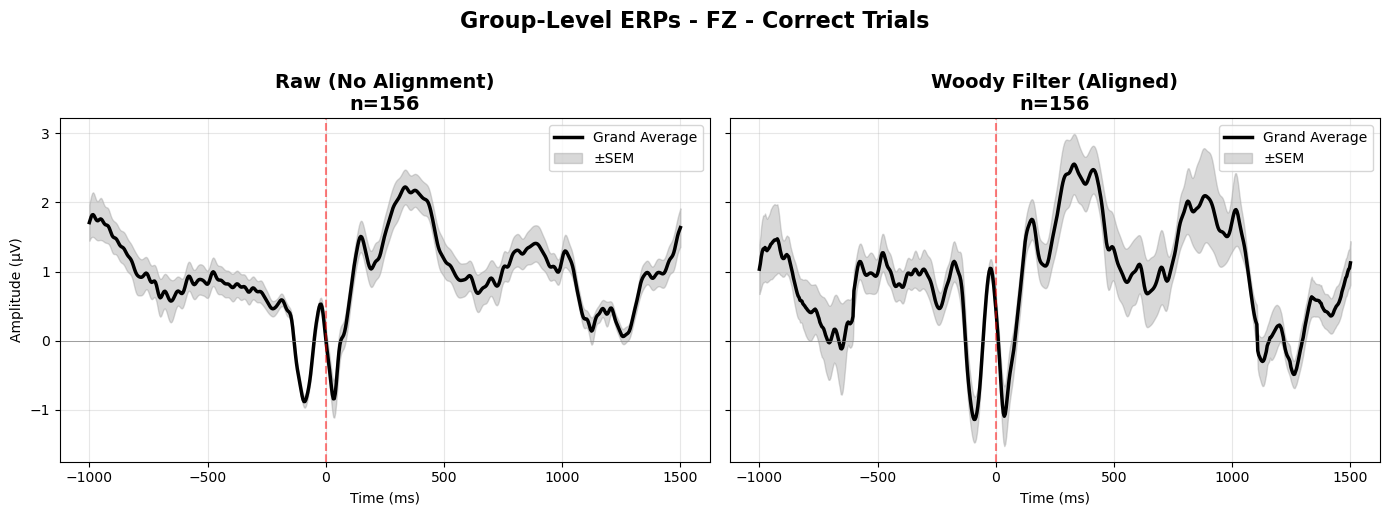

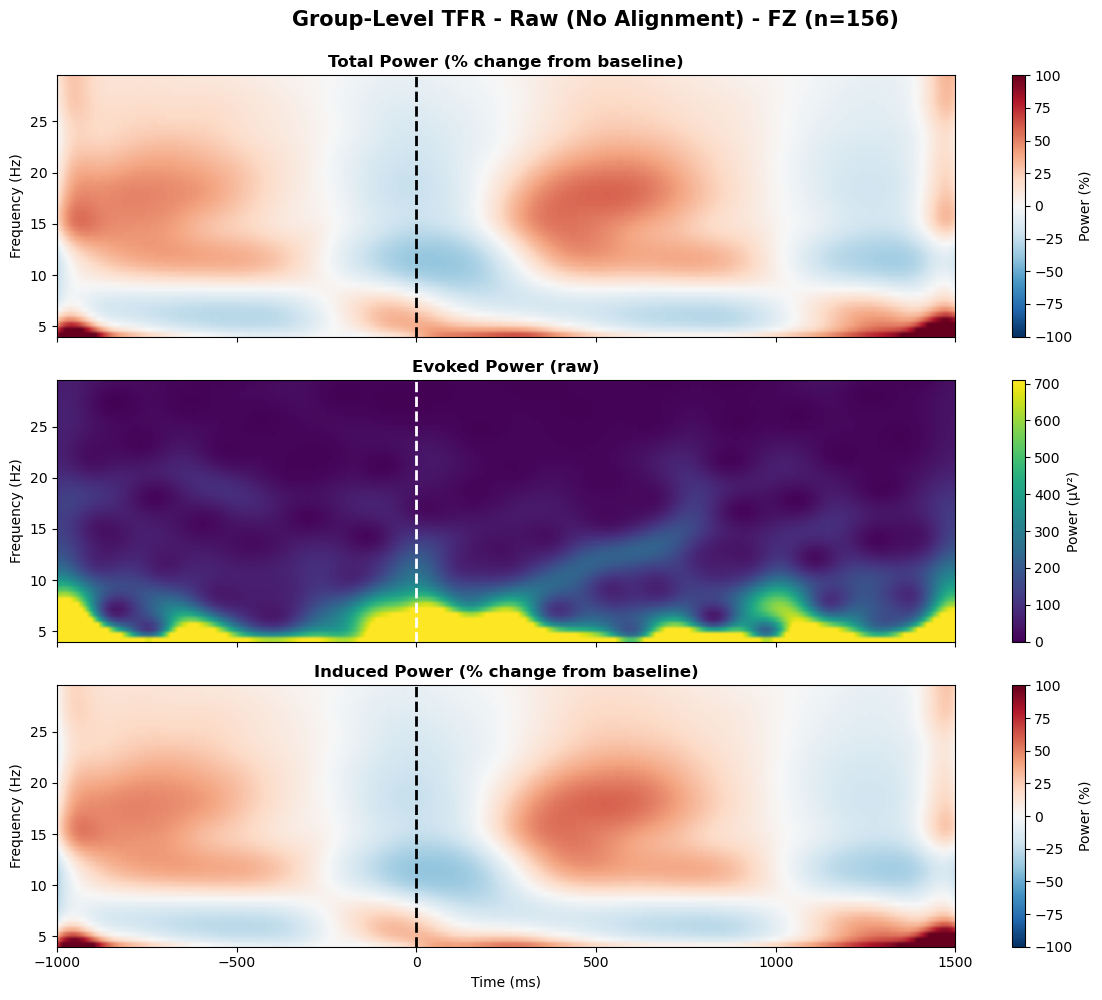

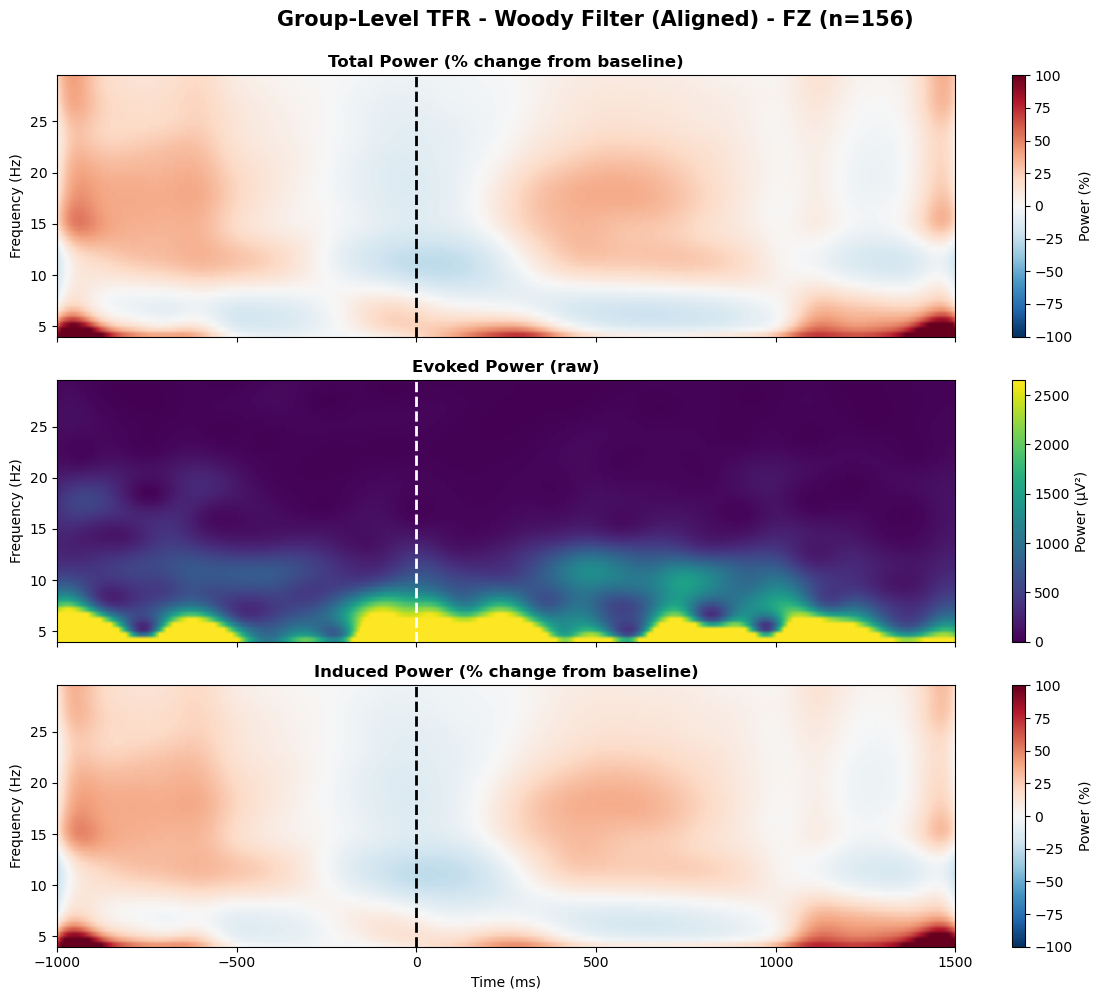

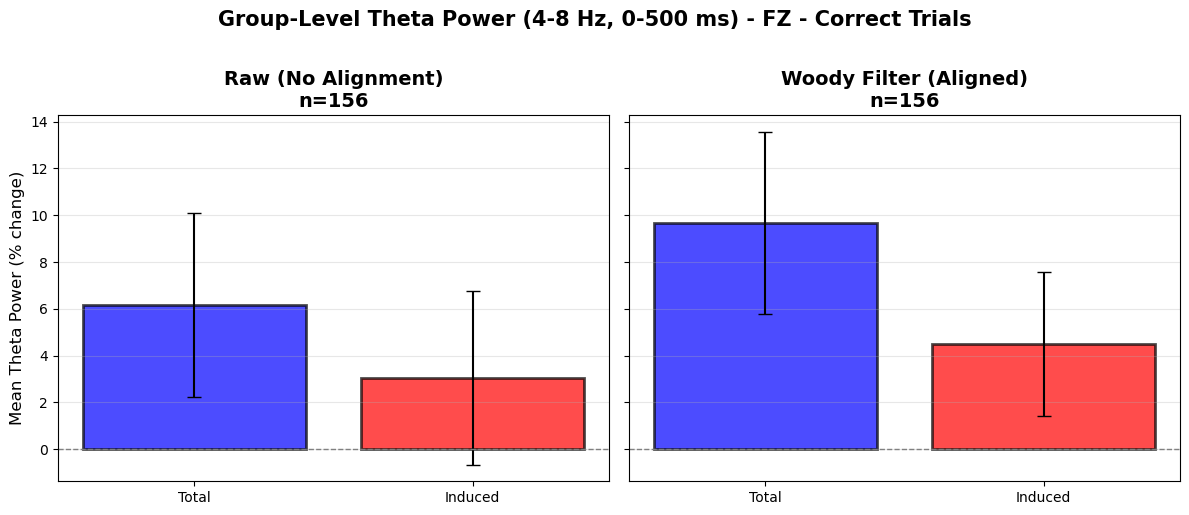


=== SUMMARY STATISTICS ===
Raw - Total: 6.17±3.94%, Induced: 3.05±3.71%
Woody - Total: 9.67±3.89%, Induced: 4.50±3.09%

Results saved to 'theta_analysis_correct.csv'


In [9]:
# Suppress warnings
warnings.filterwarnings('ignore')

def woody_filter(trials, template=None, max_shift=100):
    """Apply Woody filtering to align trials."""
    n_trials, n_times = trials.shape
    
    if template is None:
        template = trials.mean(axis=0)
    
    aligned_trials = np.zeros_like(trials)
    lags = np.zeros(n_trials, dtype=int)
    
    for i in range(n_trials):
        corr = signal.correlate(trials[i, :], template, mode='same')
        center = len(corr) // 2
        search_range = slice(center - max_shift, center + max_shift)
        lag = np.argmax(corr[search_range]) - max_shift
        lags[i] = lag
        aligned_trials[i, :] = np.roll(trials[i, :], -lag)
    
    return aligned_trials, lags

def analyze_subject(epochs_path, channel='FZ', theta_range=(4, 8), time_window=(0, 0.5)):
    """Analyze one subject: compute Raw and Woody TFR."""
    
    # Load epochs
    epochs = mne.read_epochs(epochs_path, preload=True, verbose=False)
    
    # Extract correct trials
    correct_codes = ['106', '107', '116', '117', '126', '127', '136', '137']
    epochs_correct = epochs[correct_codes]
    
    n_trials = len(epochs_correct)
    if n_trials < 5:
        return None
    
    # Get data
    data = epochs_correct.copy().pick([channel]).get_data()[:, 0, :]
    times = epochs_correct.times
    data_uv = data * 1e6
    sfreq = epochs_correct.info['sfreq']
    
    # TFR parameters
    freqs = np.arange(4, 30, 0.5)
    n_cycles = freqs / 2.0
    baseline_mask = (times >= -0.5) & (times <= 0)  # -500 to 0 ms baseline
    
    # === RAW ANALYSIS ===
    grand_avg_raw = data_uv.mean(axis=0)
    sd_raw = data_uv.std(axis=0)
    
    # Raw - Total Power
    tfr_total_raw = np.zeros((len(freqs), len(times)))
    for trial in range(n_trials):
        for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
            wavelet_duration = min(3 * n_cycle / freq, 0.5)
            wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
            wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
            convolved = np.convolve(data_uv[trial, :], wavelet, mode='same')
            tfr_total_raw[idx, :] += np.abs(convolved) ** 2
    tfr_total_raw /= n_trials
    
    # Raw - Evoked Power
    tfr_evoked_raw = np.zeros((len(freqs), len(times)))
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(grand_avg_raw, wavelet, mode='same')
        tfr_evoked_raw[idx, :] = np.abs(convolved) ** 2
    
    # Raw - Induced Power
    tfr_induced_raw = np.zeros((len(freqs), len(times)))
    for trial in range(n_trials):
        residual = data_uv[trial, :] - grand_avg_raw
        for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
            wavelet_duration = min(3 * n_cycle / freq, 0.5)
            wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
            wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
            convolved = np.convolve(residual, wavelet, mode='same')
            tfr_induced_raw[idx, :] += np.abs(convolved) ** 2
    tfr_induced_raw /= n_trials
    
    # Baseline correction
    bl_total_raw = tfr_total_raw[:, baseline_mask].mean(axis=1, keepdims=True)
    bl_induced_raw = tfr_induced_raw[:, baseline_mask].mean(axis=1, keepdims=True)
    tfr_total_raw_pct = ((tfr_total_raw - bl_total_raw) / bl_total_raw) * 100
    tfr_induced_raw_pct = ((tfr_induced_raw - bl_induced_raw) / bl_induced_raw) * 100
    
    # === WOODY ANALYSIS ===
    aligned_trials, lags = woody_filter(data_uv, max_shift=100)
    grand_avg_woody = aligned_trials.mean(axis=0)
    sd_woody = aligned_trials.std(axis=0)
    
    # Woody - Total Power
    tfr_total_woody = np.zeros((len(freqs), len(times)))
    for trial in range(n_trials):
        for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
            wavelet_duration = min(3 * n_cycle / freq, 0.5)
            wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
            wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
            convolved = np.convolve(aligned_trials[trial, :], wavelet, mode='same')
            tfr_total_woody[idx, :] += np.abs(convolved) ** 2
    tfr_total_woody /= n_trials
    
    # Woody - Evoked Power
    tfr_evoked_woody = np.zeros((len(freqs), len(times)))
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(grand_avg_woody, wavelet, mode='same')
        tfr_evoked_woody[idx, :] = np.abs(convolved) ** 2
    
    # Woody - Induced Power
    tfr_induced_woody = np.zeros((len(freqs), len(times)))
    for trial in range(n_trials):
        residual = aligned_trials[trial, :] - grand_avg_woody
        for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
            wavelet_duration = min(3 * n_cycle / freq, 0.5)
            wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
            wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
            convolved = np.convolve(residual, wavelet, mode='same')
            tfr_induced_woody[idx, :] += np.abs(convolved) ** 2
    tfr_induced_woody /= n_trials
    
    # Baseline correction
    bl_total_woody = tfr_total_woody[:, baseline_mask].mean(axis=1, keepdims=True)
    bl_induced_woody = tfr_induced_woody[:, baseline_mask].mean(axis=1, keepdims=True)
    tfr_total_woody_pct = ((tfr_total_woody - bl_total_woody) / bl_total_woody) * 100
    tfr_induced_woody_pct = ((tfr_induced_woody - bl_induced_woody) / bl_induced_woody) * 100
    
    # === EXTRACT THETA ===
    theta_mask = (freqs >= theta_range[0]) & (freqs <= theta_range[1])
    time_mask = (times >= time_window[0]) & (times <= time_window[1])
    
    results = {
        'n_trials': n_trials,
        'mean_lag': lags.mean(),
        'std_lag': lags.std(),
        'theta_total_raw': tfr_total_raw_pct[theta_mask, :][:, time_mask].mean(),
        'theta_induced_raw': tfr_induced_raw_pct[theta_mask, :][:, time_mask].mean(),
        'theta_total_woody': tfr_total_woody_pct[theta_mask, :][:, time_mask].mean(),
        'theta_induced_woody': tfr_induced_woody_pct[theta_mask, :][:, time_mask].mean(),
        'erp_raw': grand_avg_raw,
        'sd_raw': sd_raw,
        'erp_woody': grand_avg_woody,
        'sd_woody': sd_woody,
        'tfr_total_raw_pct': tfr_total_raw_pct,
        'tfr_evoked_raw': tfr_evoked_raw,
        'tfr_induced_raw_pct': tfr_induced_raw_pct,
        'tfr_total_woody_pct': tfr_total_woody_pct,
        'tfr_evoked_woody': tfr_evoked_woody,
        'tfr_induced_woody_pct': tfr_induced_woody_pct,
        'times': times,
        'freqs': freqs
    }
    
    return results

# === MAIN ANALYSIS ===
subjects = ['sub-AG05AS29', 'sub-AH17AR05', 'sub-AL07NK06', 'sub-AL08AS02', 'sub-AR06AS06', 
            'sub-AR10IO04', 'sub-AT06ED25', 'sub-AU09GE22', 'sub-CH04ER19', 'sub-CH05NK28', 
            'sub-CH06UT07', 'sub-CH07AD15', 'sub-CH09AS13', 'sub-CK04NS18', 'sub-CK06ED08', 
            'sub-CK06ST11', 'sub-CK06US15', 'sub-DADARE11', 'sub-DT05EV26', 'sub-DT07ES22', 
            'sub-DTINTZ10', 'sub-EK05AN14', 'sub-EK06ER26', 'sub-EK07CH24', 'sub-EL05JO26', 
            'sub-EL06LD17', 'sub-EL07EL14', 'sub-EN04ER01', 'sub-EN05AN02', 'sub-EN05KT02', 
            'sub-EN05US05', 'sub-EN06AN21', 'sub-EN08CH27', 'sub-EP05EN09', 'sub-ER03ER09', 
            'sub-ER04ER12', 'sub-ER04RT24', 'sub-ER05AN13', 'sub-ER05AV01', 'sub-ER05EL09', 
            'sub-ER05EL26', 'sub-ER05ER07', 'sub-ER05IM29', 'sub-ER05MA17', 'sub-ER05NG11', 
            'sub-ER05RK06', 'sub-ER05RT24', 'sub-ER06EL06', 'sub-ER06EN27', 'sub-ER06ET15', 
            'sub-ER06IS22', 'sub-ER06US24', 'sub-ER07AN28', 'sub-ER07AS24', 'sub-ER07EF15', 
            'sub-ER07EL10', 'sub-ER07ER23', 'sub-ER07ER30', 'sub-ER07RL02', 'sub-ER08AS28', 
            'sub-ER08EN05', 'sub-ER09NK30', 'sub-ES06ER27', 'sub-ES06NK11', 'sub-EZ04SE15', 
            'sub-GA04LI18', 'sub-HEERLD19', 'sub-IA05NS20', 'sub-ID07EN28', 'sub-IG06AI28', 
            'sub-IG06LF01', 'sub-IG06NS07', 'sub-IG06WE03', 'sub-IG07RT16', 'sub-IK06ET06', 
            'sub-IK09LD05', 'sub-IN05ED23', 'sub-IN06AS14', 'sub-IS06RG09', 'sub-IT08ND26', 
            'sub-JU05IN24', 'sub-KA04LF11', 'sub-KE05AN23', 'sub-KE07AN05', 'sub-KE07ER04', 
            'sub-KE08AS23', 'sub-KN05EN09', 'sub-KO07EL16', 'sub-LA08RE26', 'sub-LO06RE10', 
            'sub-LY07EL23', 'sub-MA06LO21', 'sub-ME05NS04', 'sub-NA04AV25', 'sub-ND05NG06', 
            'sub-ND06EF01', 'sub-NE06AS01', 'sub-NE06EL01', 'sub-NG03YI17', 'sub-NG06EA08', 
            'sub-NK06AS24', 'sub-NK06RG30', 'sub-NN04AN24', 'sub-NN05AN05', 'sub-NN05IR17', 
            'sub-NN06TH16', 'sub-NN07EN14', 'sub-NN07ID18', 'sub-NN08AS03', 'sub-NN08EL29', 
            'sub-NN08ER22', 'sub-NN08LM06', 'sub-NN09LM18', 'sub-NN09NS31', 'sub-NO05RT22', 
            'sub-NS09EL05', 'sub-NY04DT26', 'sub-NZ04EN16', 'sub-NZ09ER04', 'sub-OH05NK29', 
            'sub-ON05EL22', 'sub-OW07RK26', 'sub-PP07AS29', 'sub-RASUAN07', 'sub-RF09EL18', 
            'sub-RG05RS16', 'sub-RG06AS09', 'sub-RO06AN18', 'sub-RT07LD06', 'sub-RYRAAN26', 
            'sub-RZ05ND19', 'sub-SA05AH22', 'sub-SE05AS26', 'sub-SE05ZI24', 'sub-SE06AM29', 
            'sub-SE06NS17', 'sub-ST03ED03', 'sub-ST07NK15', 'sub-TA03RL11', 'sub-TE05AS09', 
            'sub-TE05NS01', 'sub-TE10AN12', 'sub-TH07AR12', 'sub-TH08ER21', 'sub-TT06LF28', 
            'sub-TT08NS17', 'sub-TZ08US31', 'sub-US07US10', 'sub-US08KE27', 'sub-VA05AS27', 
            'sub-VA05OR26', 'sub-VA06NZ29', 'sub-VA06OV12', 'sub-WA04EJ22', 'sub-WA05EJ08', 
            'sub-XX04AS28']

data_dir = Path("/Users/qmoreau/Documents/Work/flanker_bursts/PreprocessedData/ernpipeline/")

# Analyze all subjects with progress bar
all_results = []
for sub_id in tqdm(subjects, desc="Processing subjects"):
    sub_file = data_dir / sub_id / f"{sub_id}_desc-epochs_eeg.fif"
    
    if not sub_file.exists():
        continue
    
    try:
        results = analyze_subject(sub_file, channel='FZ', theta_range=(4, 8), time_window=(0, 0.5))
        if results is not None:
            results['subject'] = sub_id
            all_results.append(results)
    except:
        continue

print(f"\n{len(all_results)} subjects analyzed successfully")

# === COMPUTE GROUP AVERAGES ===
times = all_results[0]['times']
freqs = all_results[0]['freqs']

erp_raw_all = np.array([r['erp_raw'] for r in all_results])
erp_woody_all = np.array([r['erp_woody'] for r in all_results])
erp_raw_mean = erp_raw_all.mean(axis=0)
erp_raw_sem = erp_raw_all.std(axis=0) / np.sqrt(len(all_results))
erp_woody_mean = erp_woody_all.mean(axis=0)
erp_woody_sem = erp_woody_all.std(axis=0) / np.sqrt(len(all_results))

tfr_total_raw_all = np.array([r['tfr_total_raw_pct'] for r in all_results])
tfr_evoked_raw_all = np.array([r['tfr_evoked_raw'] for r in all_results])
tfr_induced_raw_all = np.array([r['tfr_induced_raw_pct'] for r in all_results])
tfr_total_woody_all = np.array([r['tfr_total_woody_pct'] for r in all_results])
tfr_evoked_woody_all = np.array([r['tfr_evoked_woody'] for r in all_results])
tfr_induced_woody_all = np.array([r['tfr_induced_woody_pct'] for r in all_results])

tfr_total_raw_mean = tfr_total_raw_all.mean(axis=0)
tfr_evoked_raw_mean = tfr_evoked_raw_all.mean(axis=0)
tfr_induced_raw_mean = tfr_induced_raw_all.mean(axis=0)
tfr_total_woody_mean = tfr_total_woody_all.mean(axis=0)
tfr_evoked_woody_mean = tfr_evoked_woody_all.mean(axis=0)
tfr_induced_woody_mean = tfr_induced_woody_all.mean(axis=0)

# === PLOT 1: ERPs ===
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

ax1.plot(times * 1000, erp_raw_mean, 'k', linewidth=2.5, label='Grand Average')
ax1.fill_between(times * 1000, erp_raw_mean - erp_raw_sem, erp_raw_mean + erp_raw_sem,
                  color='gray', alpha=0.3, label='±SEM')
ax1.axvline(0, color='r', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title(f'Raw (No Alignment)\nn={len(all_results)}', fontsize=14, fontweight='bold')
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(times * 1000, erp_woody_mean, 'k', linewidth=2.5, label='Grand Average')
ax2.fill_between(times * 1000, erp_woody_mean - erp_woody_sem, erp_woody_mean + erp_woody_sem,
                  color='gray', alpha=0.3, label='±SEM')
ax2.axvline(0, color='r', linestyle='--', alpha=0.5)
ax2.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax2.set_xlabel('Time (ms)')
ax2.set_title(f'Woody Filter (Aligned)\nn={len(all_results)}', fontsize=14, fontweight='bold')
ax2.legend()
ax2.grid(alpha=0.3)

plt.suptitle('Group-Level ERPs - FZ - Correct Trials', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# === PLOT 2: TFRs RAW ===
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

im1 = axes[0].imshow(tfr_total_raw_mean, aspect='auto', origin='lower',
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=-100, vmax=100, cmap='RdBu_r')
axes[0].axvline(0, color='black', linestyle='--', linewidth=2)
axes[0].set_ylabel('Frequency (Hz)')
axes[0].set_title('Total Power (% change from baseline)', fontweight='bold')
plt.colorbar(im1, ax=axes[0], label='Power (%)')

vmax_evoked = np.percentile(tfr_evoked_raw_mean, 95)
im2 = axes[1].imshow(tfr_evoked_raw_mean, aspect='auto', origin='lower',
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=0, vmax=vmax_evoked, cmap='viridis')
axes[1].axvline(0, color='white', linestyle='--', linewidth=2)
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_title('Evoked Power (raw)', fontweight='bold')
plt.colorbar(im2, ax=axes[1], label='Power (µV²)')

im3 = axes[2].imshow(tfr_induced_raw_mean, aspect='auto', origin='lower',
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=-100, vmax=100, cmap='RdBu_r')
axes[2].axvline(0, color='black', linestyle='--', linewidth=2)
axes[2].set_xlabel('Time (ms)')
axes[2].set_ylabel('Frequency (Hz)')
axes[2].set_title('Induced Power (% change from baseline)', fontweight='bold')
plt.colorbar(im3, ax=axes[2], label='Power (%)')

plt.suptitle(f'Group-Level TFR - Raw (No Alignment) - FZ (n={len(all_results)})',
             fontsize=15, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

# === PLOT 3: TFRs WOODY ===
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

im1 = axes[0].imshow(tfr_total_woody_mean, aspect='auto', origin='lower',
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=-100, vmax=100, cmap='RdBu_r')
axes[0].axvline(0, color='black', linestyle='--', linewidth=2)
axes[0].set_ylabel('Frequency (Hz)')
axes[0].set_title('Total Power (% change from baseline)', fontweight='bold')
plt.colorbar(im1, ax=axes[0], label='Power (%)')

vmax_evoked = np.percentile(tfr_evoked_woody_mean, 95)
im2 = axes[1].imshow(tfr_evoked_woody_mean, aspect='auto', origin='lower',
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=0, vmax=vmax_evoked, cmap='viridis')
axes[1].axvline(0, color='white', linestyle='--', linewidth=2)
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_title('Evoked Power (raw)', fontweight='bold')
plt.colorbar(im2, ax=axes[1], label='Power (µV²)')

im3 = axes[2].imshow(tfr_induced_woody_mean, aspect='auto', origin='lower',
                     extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                     vmin=-100, vmax=100, cmap='RdBu_r')
axes[2].axvline(0, color='black', linestyle='--', linewidth=2)
axes[2].set_xlabel('Time (ms)')
axes[2].set_ylabel('Frequency (Hz)')
axes[2].set_title('Induced Power (% change from baseline)', fontweight='bold')
plt.colorbar(im3, ax=axes[2], label='Power (%)')

plt.suptitle(f'Group-Level TFR - Woody Filter (Aligned) - FZ (n={len(all_results)})',
             fontsize=15, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

# === PLOT 4: THETA BARPLOTS ===
df = pd.DataFrame([{k: v for k, v in r.items() if k not in ['erp_raw', 'sd_raw', 'erp_woody', 'sd_woody',
                                                               'tfr_total_raw_pct', 'tfr_evoked_raw', 'tfr_induced_raw_pct',
                                                               'tfr_total_woody_pct', 'tfr_evoked_woody', 'tfr_induced_woody_pct',
                                                               'times', 'freqs']} for r in all_results])

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

raw_means = [df['theta_total_raw'].mean(), df['theta_induced_raw'].mean()]
raw_sems = [df['theta_total_raw'].sem(), df['theta_induced_raw'].sem()]
x_pos = np.arange(len(raw_means))
axes[0].bar(x_pos, raw_means, yerr=raw_sems, color=['blue', 'red'],
            alpha=0.7, edgecolor='black', linewidth=2, capsize=5)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(['Total', 'Induced'])
axes[0].axhline(0, color='gray', linestyle='--', linewidth=1)
axes[0].set_ylabel('Mean Theta Power (% change)', fontsize=12)
axes[0].set_title(f'Raw (No Alignment)\nn={len(df)}', fontsize=14, fontweight='bold')
axes[0].grid(alpha=0.3, axis='y')

woody_means = [df['theta_total_woody'].mean(), df['theta_induced_woody'].mean()]
woody_sems = [df['theta_total_woody'].sem(), df['theta_induced_woody'].sem()]
axes[1].bar(x_pos, woody_means, yerr=woody_sems, color=['blue', 'red'],
            alpha=0.7, edgecolor='black', linewidth=2, capsize=5)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(['Total', 'Induced'])
axes[1].axhline(0, color='gray', linestyle='--', linewidth=1)
axes[1].set_title(f'Woody Filter (Aligned)\nn={len(df)}', fontsize=14, fontweight='bold')
axes[1].grid(alpha=0.3, axis='y')

plt.suptitle('Group-Level Theta Power (4-8 Hz, 0-500 ms) - FZ - Correct Trials',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\n=== SUMMARY STATISTICS ===")
print(f"Raw - Total: {raw_means[0]:.2f}±{raw_sems[0]:.2f}%, Induced: {raw_means[1]:.2f}±{raw_sems[1]:.2f}%")
print(f"Woody - Total: {woody_means[0]:.2f}±{woody_sems[0]:.2f}%, Induced: {woody_means[1]:.2f}±{woody_sems[1]:.2f}%")

df.to_csv('theta_analysis_correct.csv', index=False)
print("\nResults saved to 'theta_analysis_correct.csv'")

Matched subjects: 155

=== PAIRED T-TEST RESULTS ===

Raw (No Alignment):
  Error:   M = 42.98, SD = 69.51
  Correct: M = 3.47, SD = 46.24
  t(154) = 12.428, p = 0.0000, d = 0.998

Woody Filter (Aligned):
  Error:   M = 23.86, SD = 47.91
  Correct: M = 4.85, SD = 38.49
  t(154) = 8.533, p = 0.0000, d = 0.685


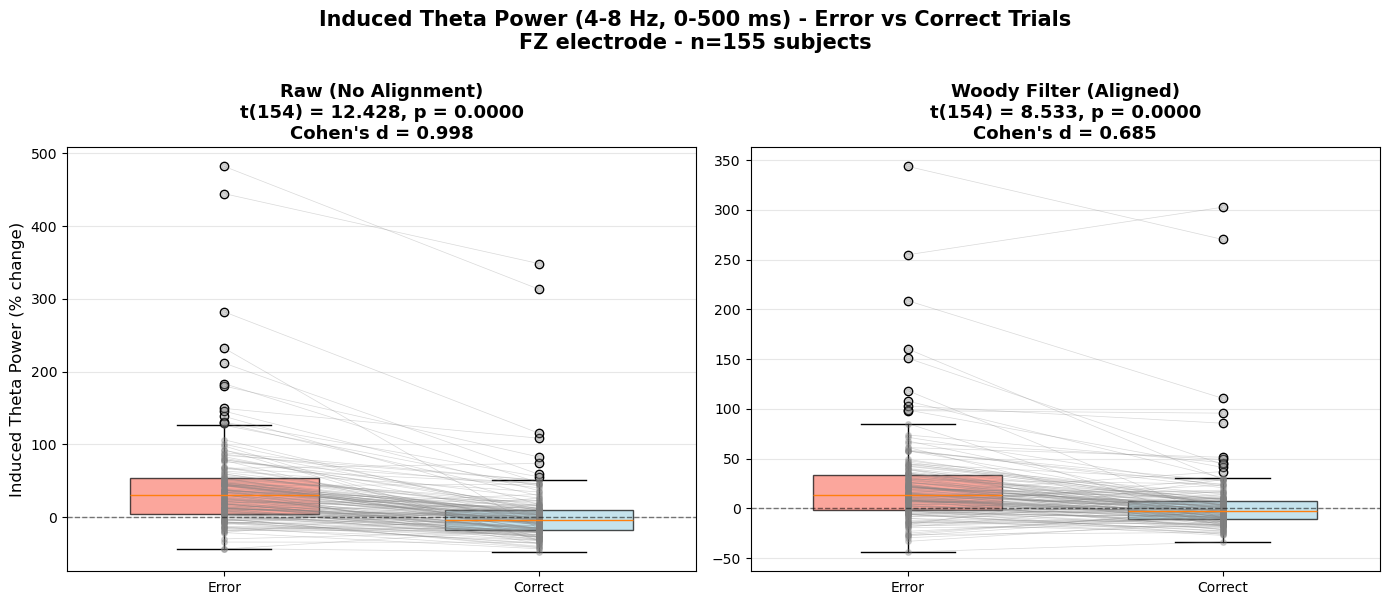

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

# Load results from both analyses
df_error = pd.read_csv('theta_analysis_results.csv')
df_correct = pd.read_csv('theta_analysis_correct.csv')

# Merge datasets on subject ID to ensure matched pairs
df_merged = pd.merge(df_error[['subject', 'theta_induced_raw', 'theta_induced_woody']], 
                     df_correct[['subject', 'theta_induced_raw', 'theta_induced_woody']], 
                     on='subject', 
                     suffixes=('_error', '_correct'))

print(f"Matched subjects: {len(df_merged)}")

# Perform paired t-tests
# Raw (no alignment)
t_raw, p_raw = stats.ttest_rel(df_merged['theta_induced_raw_error'], 
                                df_merged['theta_induced_raw_correct'])

# Woody filtered
t_woody, p_woody = stats.ttest_rel(df_merged['theta_induced_woody_error'], 
                                    df_merged['theta_induced_woody_correct'])

# Calculate effect sizes (Cohen's d for paired samples)
def cohens_d_paired(x, y):
    diff = x - y
    return diff.mean() / diff.std()

d_raw = cohens_d_paired(df_merged['theta_induced_raw_error'], 
                        df_merged['theta_induced_raw_correct'])
d_woody = cohens_d_paired(df_merged['theta_induced_woody_error'], 
                          df_merged['theta_induced_woody_correct'])

# Print statistics
print("\n=== PAIRED T-TEST RESULTS ===")
print(f"\nRaw (No Alignment):")
print(f"  Error:   M = {df_merged['theta_induced_raw_error'].mean():.2f}, SD = {df_merged['theta_induced_raw_error'].std():.2f}")
print(f"  Correct: M = {df_merged['theta_induced_raw_correct'].mean():.2f}, SD = {df_merged['theta_induced_raw_correct'].std():.2f}")
print(f"  t({len(df_merged)-1}) = {t_raw:.3f}, p = {p_raw:.4f}, d = {d_raw:.3f}")

print(f"\nWoody Filter (Aligned):")
print(f"  Error:   M = {df_merged['theta_induced_woody_error'].mean():.2f}, SD = {df_merged['theta_induced_woody_error'].std():.2f}")
print(f"  Correct: M = {df_merged['theta_induced_woody_correct'].mean():.2f}, SD = {df_merged['theta_induced_woody_correct'].std():.2f}")
print(f"  t({len(df_merged)-1}) = {t_woody:.3f}, p = {p_woody:.4f}, d = {d_woody:.3f}")

# Create visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Prepare data for boxplots
data_raw = [df_merged['theta_induced_raw_error'], df_merged['theta_induced_raw_correct']]
data_woody = [df_merged['theta_induced_woody_error'], df_merged['theta_induced_woody_correct']]

# Raw boxplot
bp1 = axes[0].boxplot(data_raw, labels=['Error', 'Correct'], patch_artist=True,
                      widths=0.6, showfliers=True)
for patch, color in zip(bp1['boxes'], ['salmon', 'lightblue']):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

# Add individual points with connecting lines
for i in range(len(df_merged)):
    axes[0].plot([1, 2], 
                [df_merged['theta_induced_raw_error'].iloc[i], 
                 df_merged['theta_induced_raw_correct'].iloc[i]], 
                'o-', color='gray', alpha=0.3, markersize=4, linewidth=0.5)

axes[0].set_ylabel('Induced Theta Power (% change)', fontsize=12)
axes[0].set_title(f'Raw (No Alignment)\nt({len(df_merged)-1}) = {t_raw:.3f}, p = {p_raw:.4f}\nCohen\'s d = {d_raw:.3f}', 
                 fontsize=13, fontweight='bold')
axes[0].grid(alpha=0.3, axis='y')
axes[0].axhline(0, color='black', linestyle='--', linewidth=1, alpha=0.5)

# Woody boxplot
bp2 = axes[1].boxplot(data_woody, labels=['Error', 'Correct'], patch_artist=True,
                      widths=0.6, showfliers=True)
for patch, color in zip(bp2['boxes'], ['salmon', 'lightblue']):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

# Add individual points with connecting lines
for i in range(len(df_merged)):
    axes[1].plot([1, 2], 
                [df_merged['theta_induced_woody_error'].iloc[i], 
                 df_merged['theta_induced_woody_correct'].iloc[i]], 
                'o-', color='gray', alpha=0.3, markersize=4, linewidth=0.5)

axes[1].set_title(f'Woody Filter (Aligned)\nt({len(df_merged)-1}) = {t_woody:.3f}, p = {p_woody:.4f}\nCohen\'s d = {d_woody:.3f}', 
                 fontsize=13, fontweight='bold')
axes[1].grid(alpha=0.3, axis='y')
axes[1].axhline(0, color='black', linestyle='--', linewidth=1, alpha=0.5)

plt.suptitle(f'Induced Theta Power (4-8 Hz, 0-500 ms) - Error vs Correct Trials\nFZ electrode - n={len(df_merged)} subjects', 
             fontsize=15, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()
